In [2]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from pathlib import Path
import pandas as pd
import seaborn as sns
import numpy as np
%load_ext autoreload
%autoreload 2

from fwh_analysis import FWHDataset, FWHPlotter

def p_element_plot(dataframe, title=None):
    """ Returns P vs Element Matrix as an alternative to P vs X Matrix """
    norm = mcolors.LogNorm(vmin = 1e-3, vmax=1e-1)
    cmap = cm.coolwarm

    fig, ax = plt.subplots(figsize=[8,6])
    color_val = cmap(norm(dataframe['error']))
    ax.scatter(dataframe['elements'] / 1000, dataframe['P'], color=color_val)

    sm = plt.cm.ScalarMappable(cmap = cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax)
    cbar.set_label("Log Error (%)")

    ax.set_xlabel(f"Element Count $(10^3)$")
    # ax.set_xscale('log')
    ax.set_ylabel("Temporal Resolution, P (Points Per Period)")
    ax.set_title(title)

    plt.show()

def line_plot(df, p_val=80, x_val=100, mach_number=0.0, radius=20.0):
    p = df[df['P'] == p_val].sort_values(by='X')
    x = df[df['X'] == x_val].sort_values(by='P')

    fig, (ax1, ax2) = plt.subplots(1,2, sharey=True, figsize=(12,4))
    ax1.scatter(p['X'], p['error'])
    ax1.plot(p['X'], p['error'])
    ax1.set_yscale('log')
    ax1.set_ylim(1e-3, 5e-1)
    ax1.set_xlabel(f"Spatial Resolution, X ($\lambda$/d)")
    ax1.set_ylabel("Log Error (%)")
    ax1.grid(True, which='both')
    ax1.set_title(f'Constant P at {p_val}')

    ax2.scatter(x['P'], x['error'])
    ax2.plot(x['P'], x['error'])
    ax2.set_xlabel(f"Temporal Resolution, P ($f_{{sample}} / f_{{s}}$)")
    ax2.grid(True, which='both')
    ax2.set_title(f'Constant X at {x_val}')

    fig.suptitle(f'Error vs Parameterised Time Step/Grid Size, M={mach_number}, R={radius}')
    plt.show()

def box_plotter(folder_list):
    master = []
    for folder in folder_list:
        master.extend(FWHDataset.compile_fwh_batch(folder, use_doppler=True))

    df = pd.DataFrame(master)
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.boxplot(data=df, x='batch_name', y='error', palette='coolwarm', 
                boxprops=dict(edgecolor='black'), medianprops=dict(color='red', linewidth=2),
                showfliers=False, ax=ax)

    medians = df.groupby('batch_name')['error'].median()
    obs_names = df['batch_name'].unique()

    for i, obs in enumerate(obs_names):
        median_val = medians[obs]
        text_label = f"{median_val:.2e}" 
        ax.text(i, median_val * 1.05, text_label, 
                horizontalalignment='center', size='small', color='black', weight='bold')

    ax.set_yscale('log')
    ax.set_ylabel('L2 Error (%)')
    ax.set_ylim(5e-4, 3e-2)
    ax.set_xlabel('Observer ID (Front to Rear)')
    ax.set_title('Multiple Observer Error Variance - Interquartile Range')
    ax.grid(True, axis='y', linestyle='--', alpha=0.6, which='both')

    plt.show()
    return df

<>:44: SyntaxWarning: invalid escape sequence '\l'
<>:44: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_217433/1567178829.py:44: SyntaxWarning: invalid escape sequence '\l'
  ax1.set_xlabel(f"Spatial Resolution, X ($\lambda$/d)")
/home/abi/Documents/FWH/postprocess/aeroacoustics_postprocess/fwh_analysis.py:383: SyntaxWarning: invalid escape sequence '\l'
  ax.set_xlabel(f"Spatial Resolution ($\lambda / d$)")
/home/abi/Documents/FWH/postprocess/aeroacoustics_postprocess/fwh_analysis.py:386: SyntaxWarning: invalid escape sequence '\l'
  ax.set_xlabel(f"Normalised Radius (R / $\lambda$)")


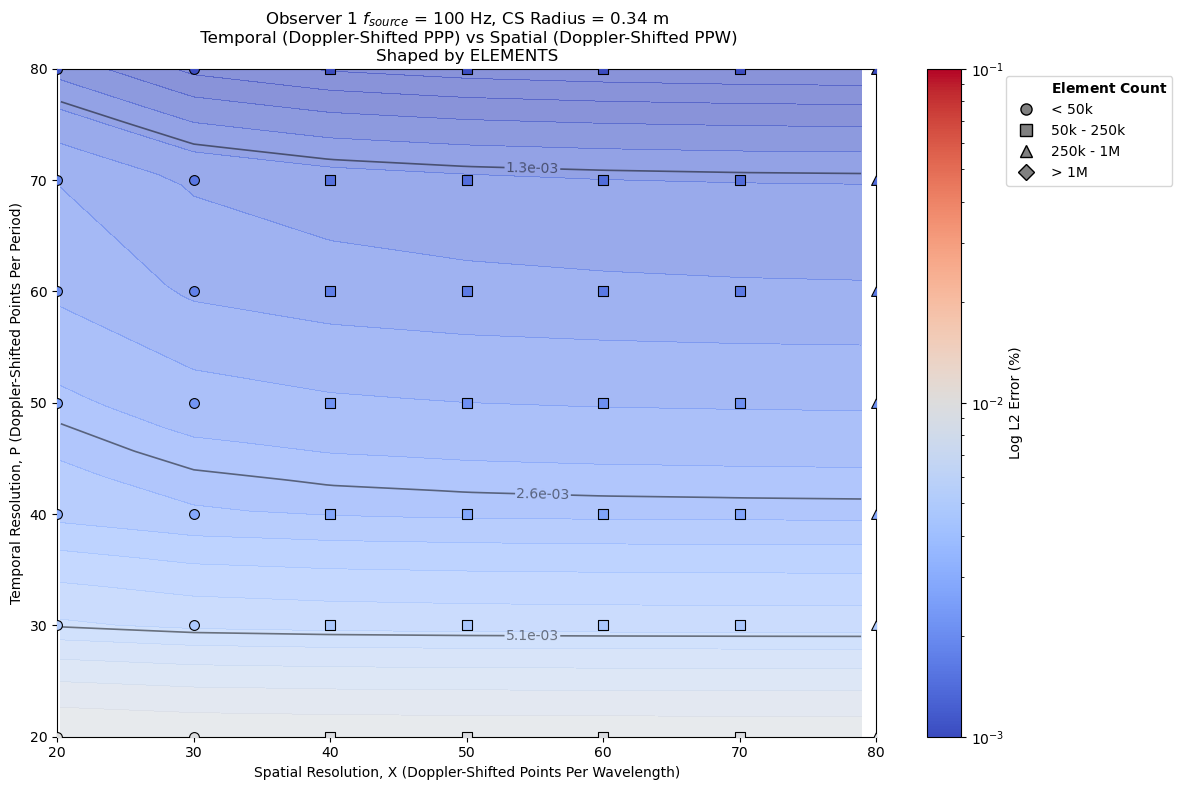

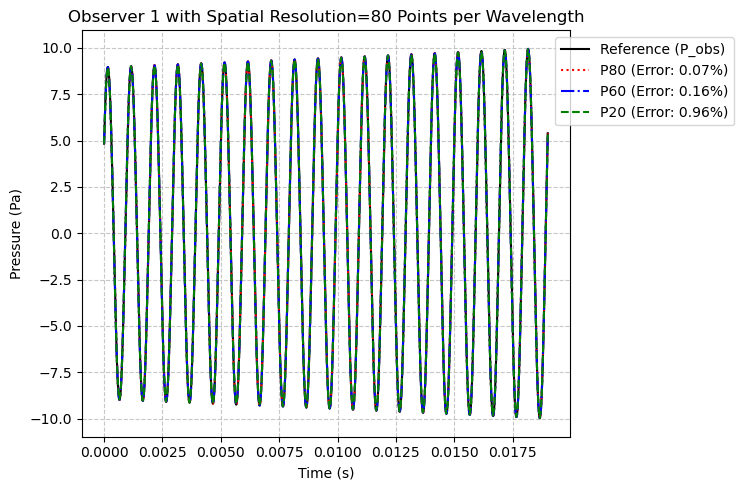

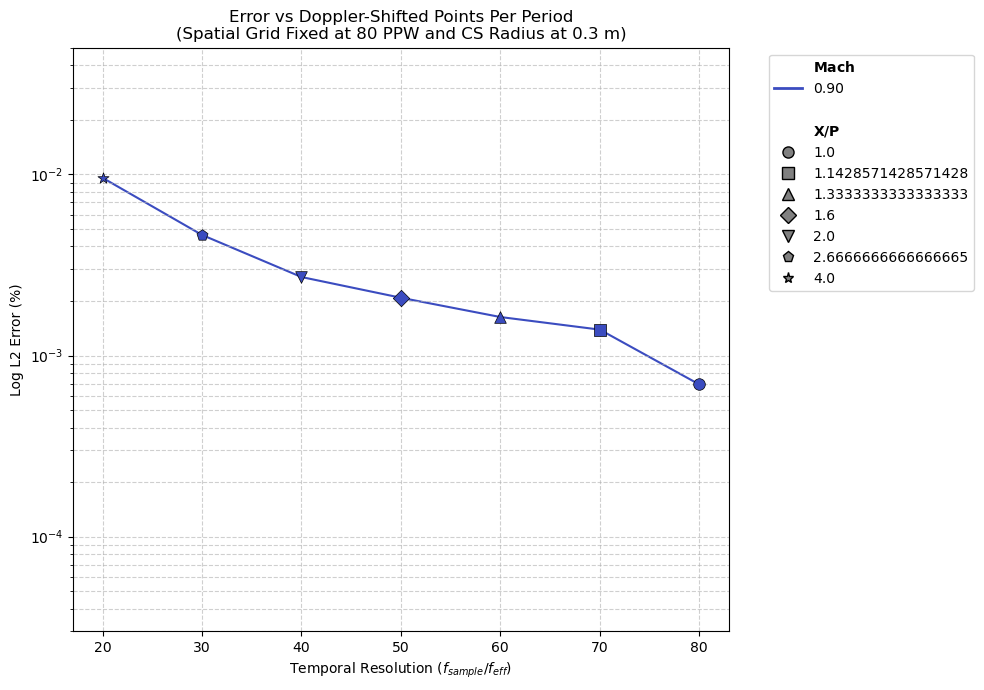

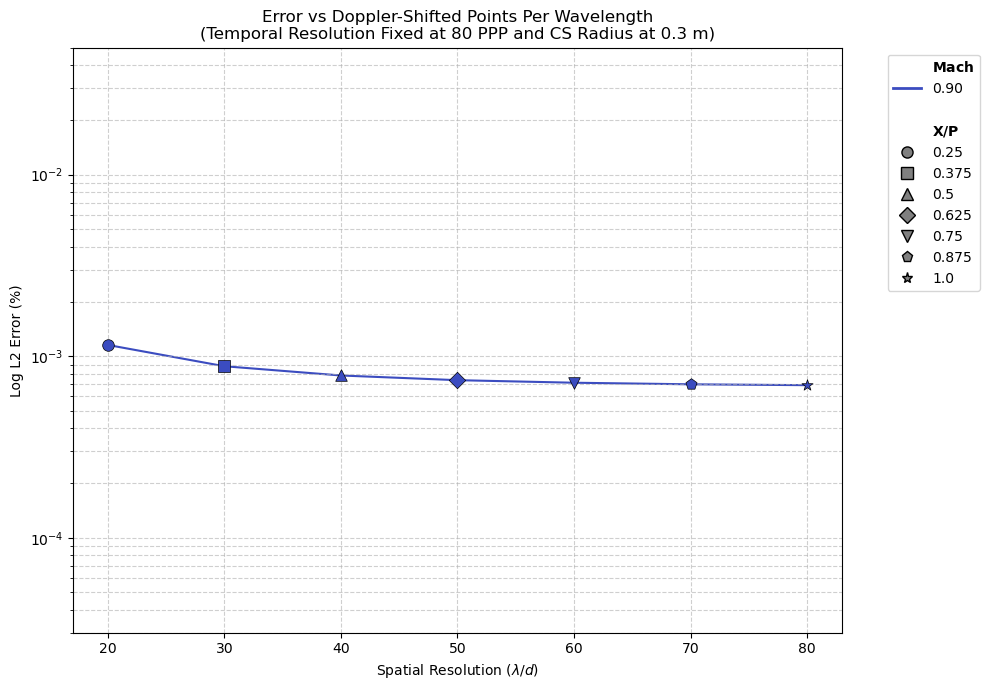

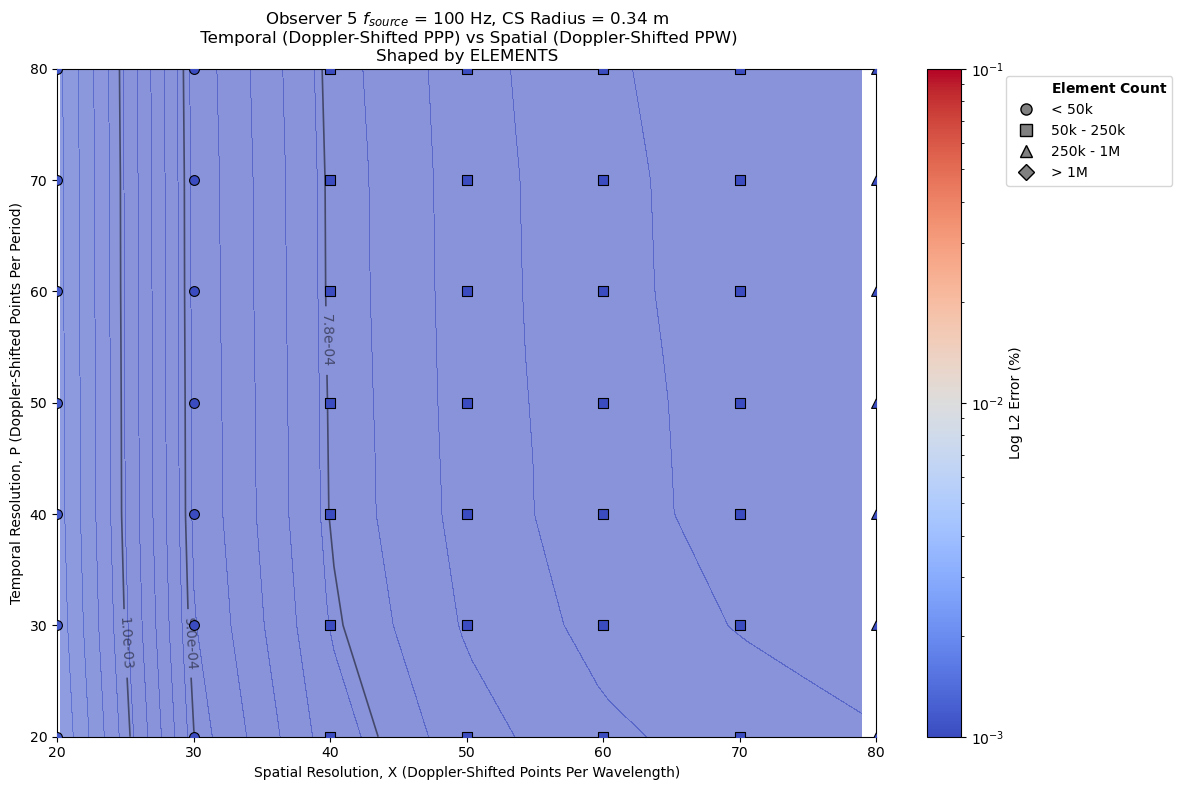

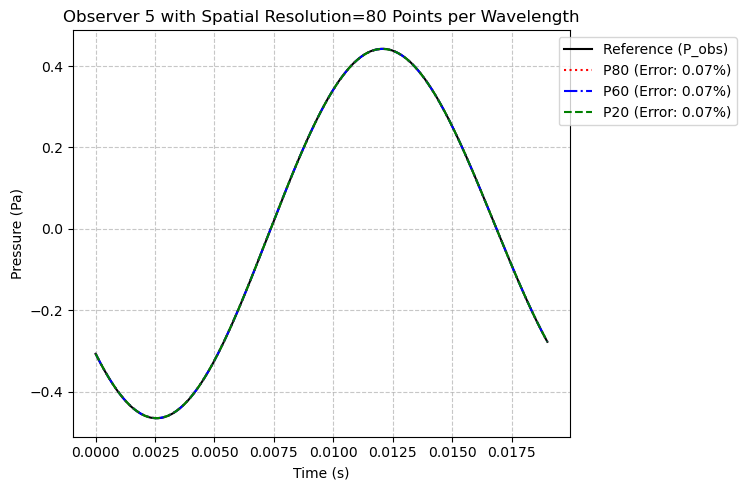

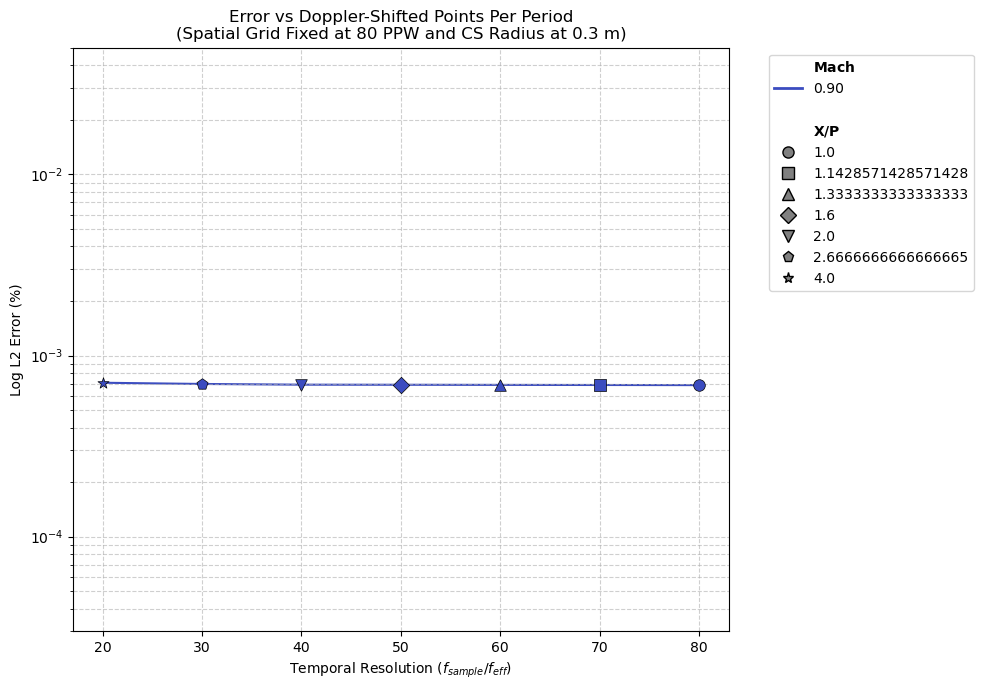

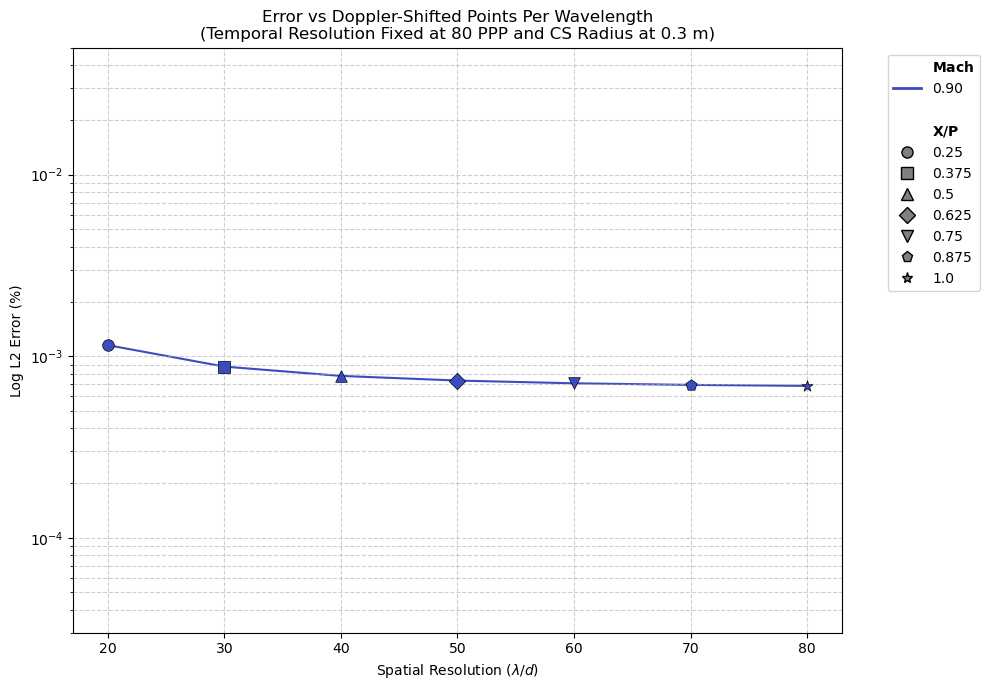

/tmp/ipykernel_217433/1567178829.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='batch_name', y='error', palette='coolwarm',


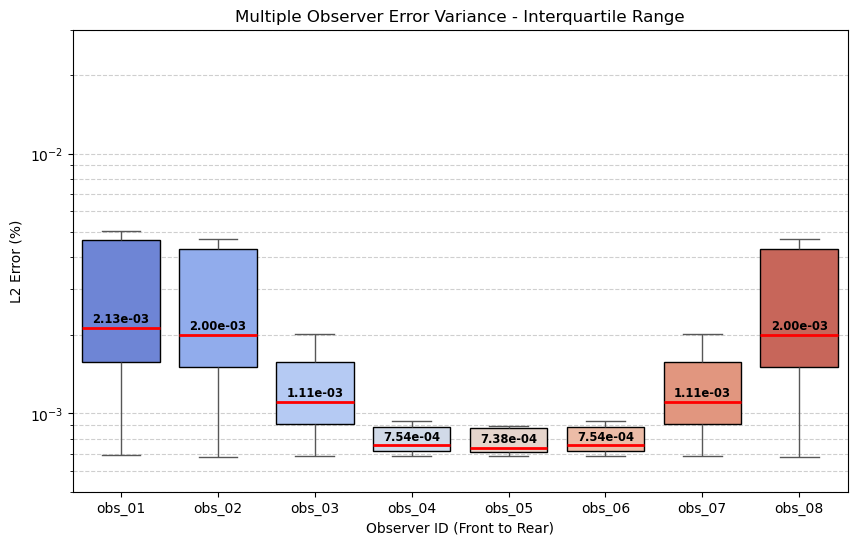

,mach,cfl,dt,P,X,error,elements,batch_name
0,0.9,2.000000,0.000025,40.000000,80.000000,0.002712,253009,obs_01
1,0.9,1.400000,0.000020,50.000000,70.000000,0.002091,193600,obs_01
2,0.9,0.428571,0.000014,70.000001,30.000001,0.001574,35344,obs_01
3,0.9,0.833333,0.000017,59.999999,49.999999,0.001674,98596,obs_01
4,0.9,0.250000,0.000013,80.000000,20.000000,0.001154,15876,obs_01
...,...,...,...,...,...,...,...,...
387,0.9,0.600000,0.000020,50.000000,30.000000,0.002138,35344,obs_08
388,0.9,1.200000,0.000020,50.000000,60.000000,0.001979,142129,obs_08
389,0.9,1.000000,0.000050,20.000000,20.000000,0.009171,15876,obs_08
390,0.9,0.333333,0.000017,59.999999,20.000000,0.001989,15876,obs_08


In [9]:
### Moving Monopole, Multiple Observers, R/lambda = 1 ###
FWHDataset.F_SOURCE = 100
FWHDataset.OMEGA = 2 * np.pi * FWHDataset.F_SOURCE
FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE
FWHDataset.R = FWHDataset.LAMBDA_SOURCE * (1 - 0.9)

folders = [
    'data_260625/multi_mono_90M_100hz/obs_01',
    'data_260625/multi_mono_90M_100hz/obs_02',
    'data_260625/multi_mono_90M_100hz/obs_03',
    'data_260625/multi_mono_90M_100hz/obs_04',
    'data_260625/multi_mono_90M_100hz/obs_05',
    'data_260625/multi_mono_90M_100hz/obs_06',
    'data_260625/multi_mono_90M_100hz/obs_07',
    'data_260625/multi_mono_90M_100hz/obs_08',
]

obs = [0, 4]
for i in obs:
    filepath = Path(folders[i])
    data = FWHDataset.compile_fwh_batch(filepath)
    analytical = FWHDataset(filepath / 'ana_M90.dat')
    title = f"Observer {i+1} $f_{{source}}$ = {FWHDataset.F_SOURCE} Hz, CS Radius = {FWHDataset.R:.2f} m"

    # FWHPlotter.plot_px_parameter_space(data, use_doppler=True, legend=True,
    #                                 add_title=title)

    FWHPlotter.plot_px_contour_space(data, use_doppler=True, add_title=title)
    
    FWHPlotter.plot_pressure(analytical, 
                            FWHDataset(filepath / "P80_X80_M90.dat"), 
                            FWHDataset(filepath / "P60_X80_M90.dat"),
                            FWHDataset(filepath / "P20_X80_M90.dat"),
                            ref_col='P_obs',
                            labels=['P80','P60','P20'],
                            title=f'Observer {i+1} with Spatial Resolution=80 Points per Wavelength')

    FWHPlotter.plot_cfl_convergence_by_mach(filepath, 'dt', analytical, [80, FWHDataset.R], use_doppler=True, legend=True)
    FWHPlotter.plot_cfl_convergence_by_mach(filepath, 'dx', analytical, [80, FWHDataset.R], use_doppler=True, legend=True)

box_plotter(folders)

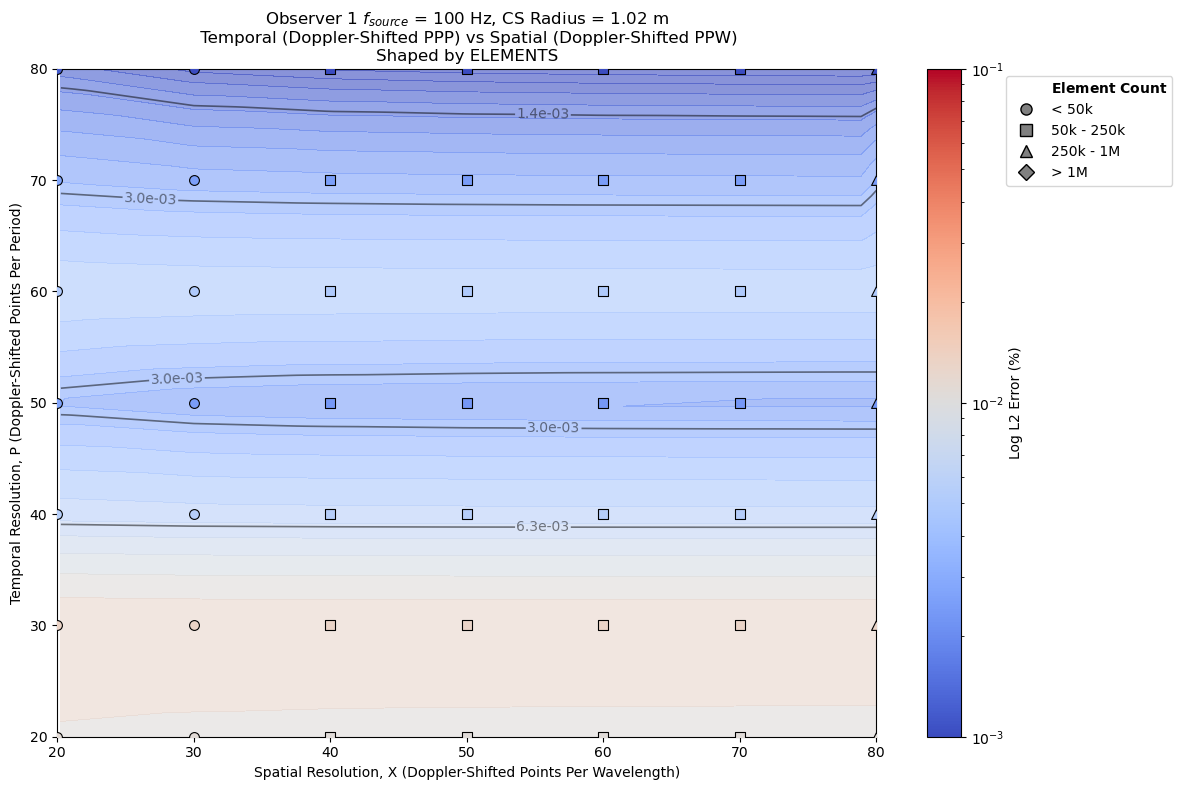

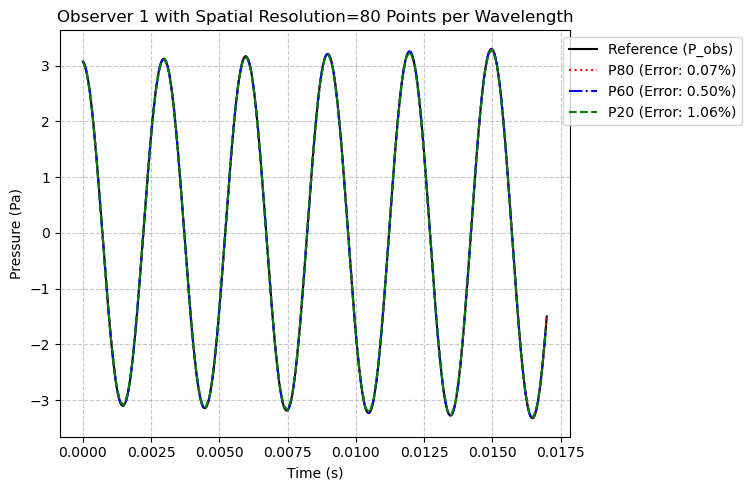

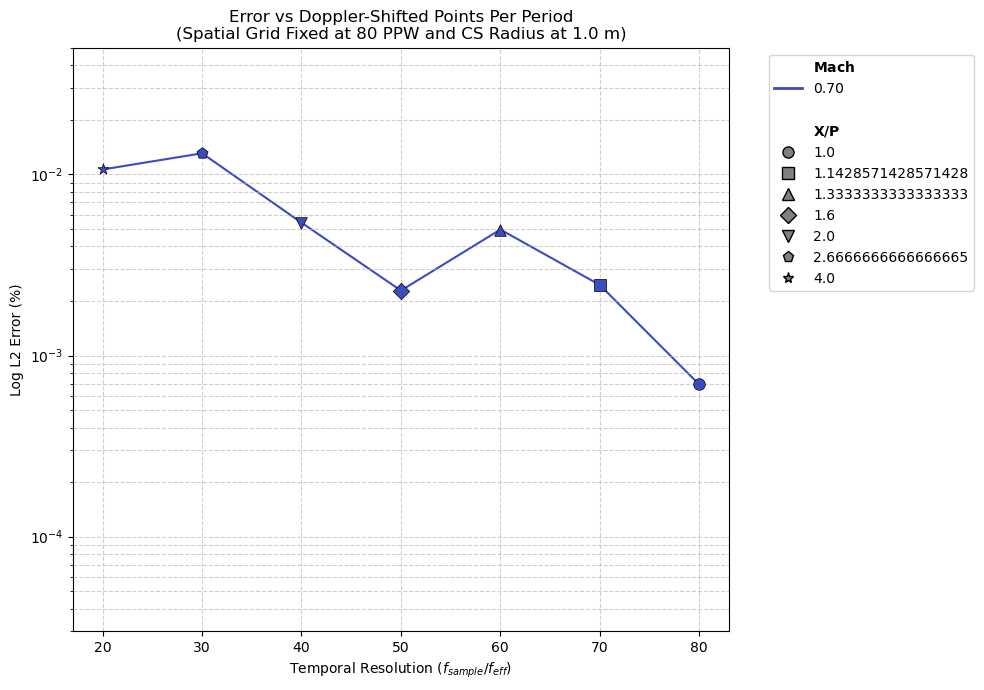

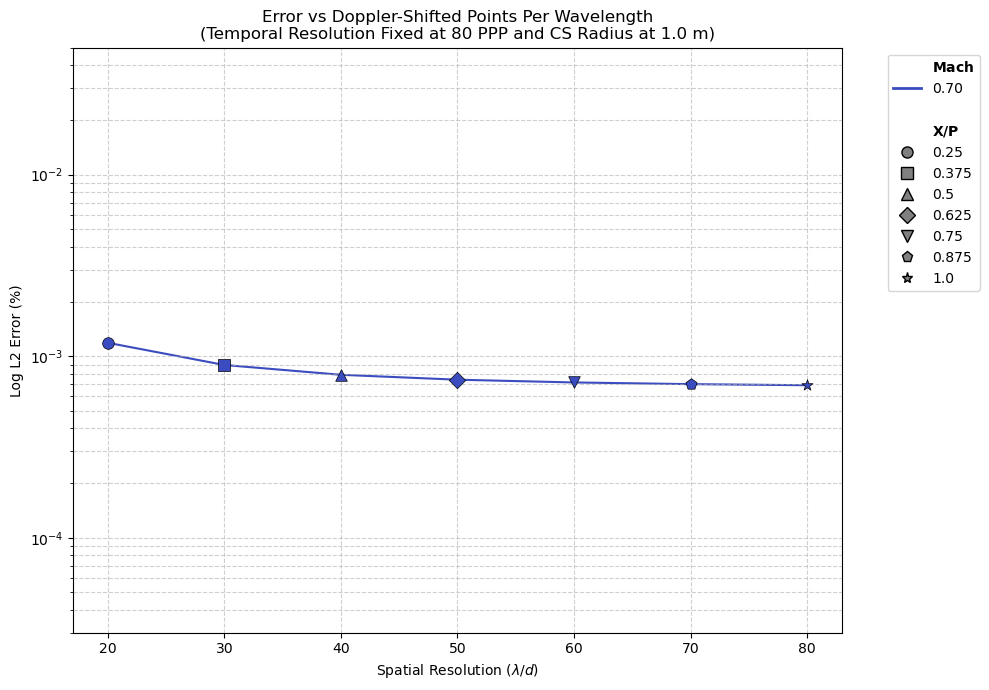

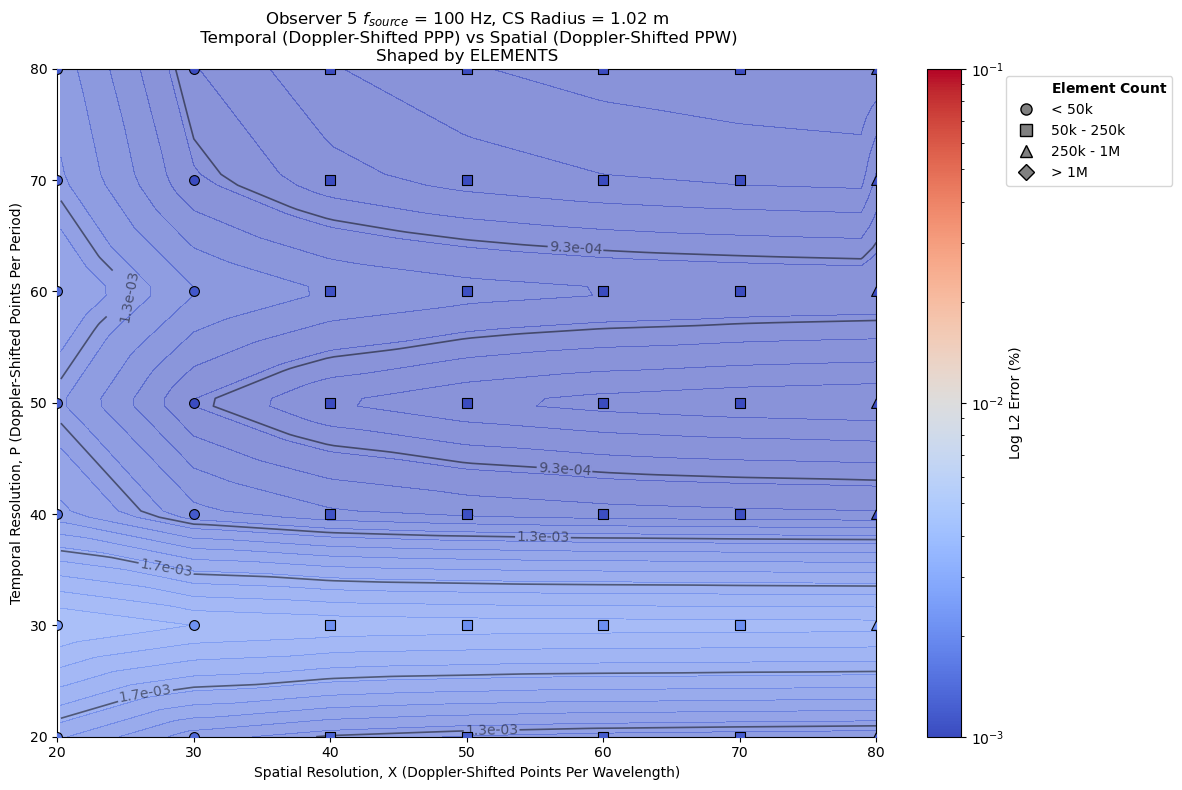

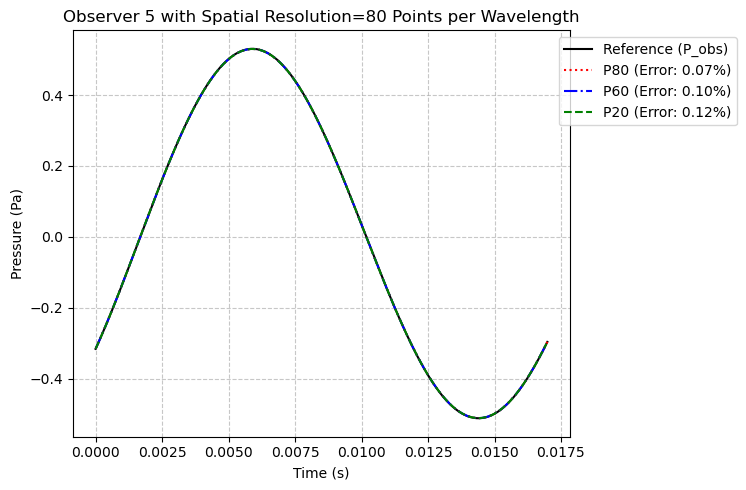

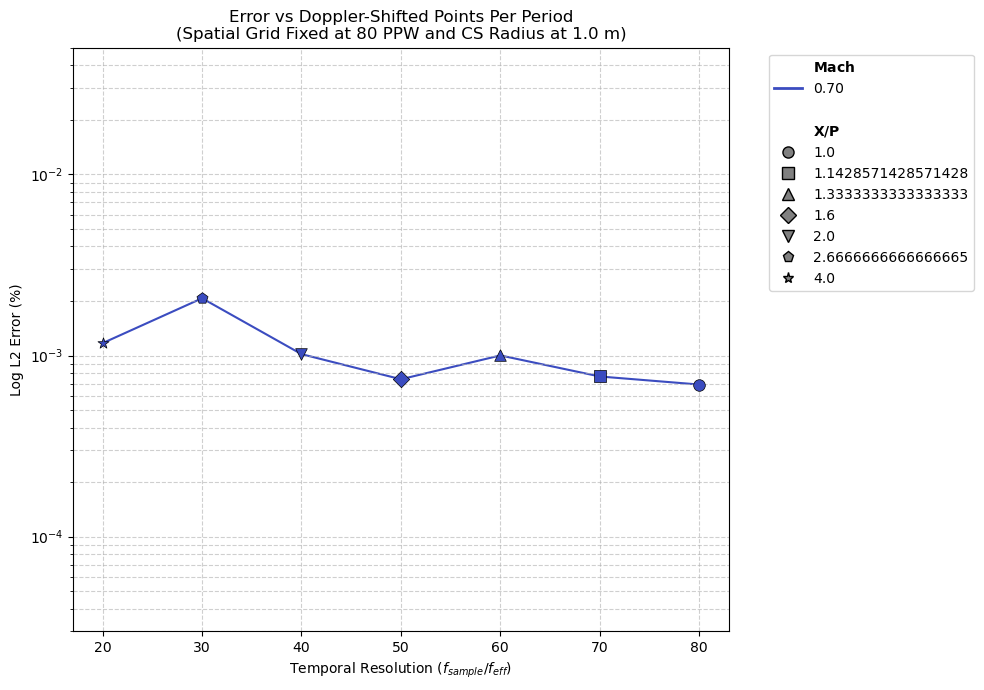

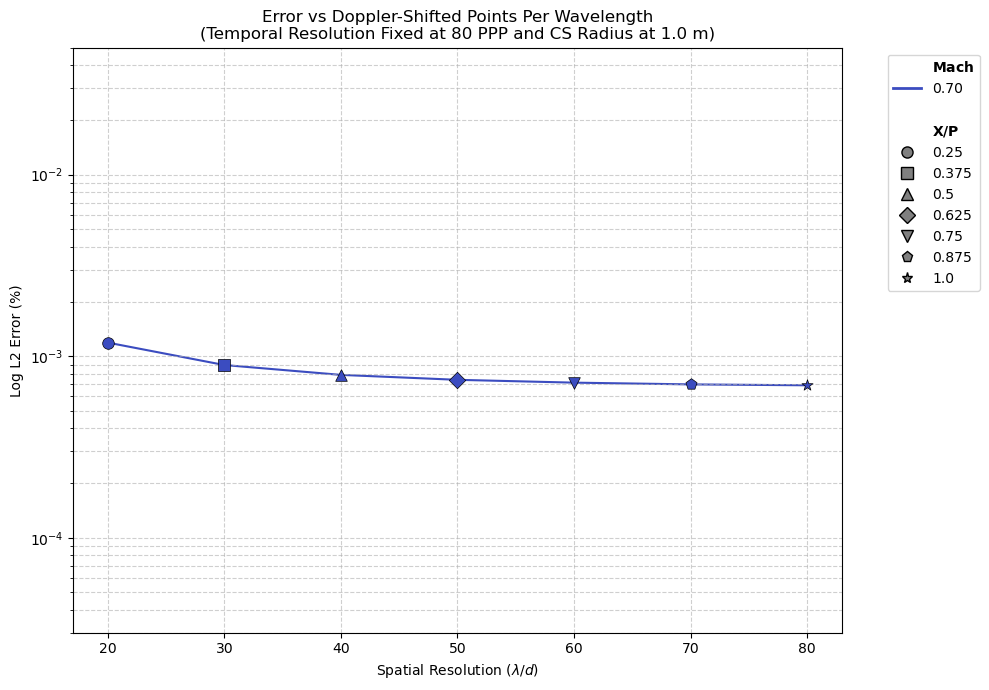

/tmp/ipykernel_217433/1567178829.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='batch_name', y='error', palette='coolwarm',


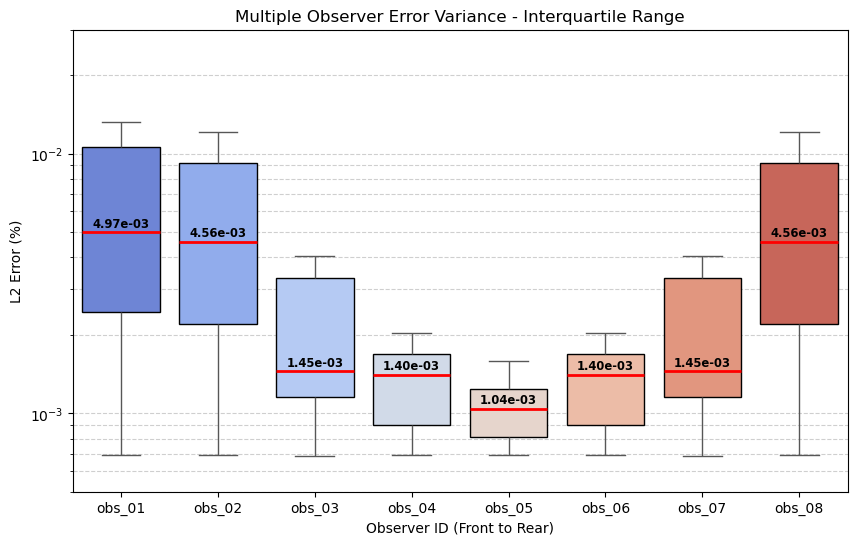

,mach,cfl,dt,P,X,error,elements,batch_name
0,0.7,2.000000,0.000100,30.0,60.0,0.013075,142129,obs_01
1,0.7,0.714286,0.000043,70.0,50.0,0.002479,98596,obs_01
2,0.7,1.500000,0.000150,20.0,30.0,0.010793,35344,obs_01
3,0.7,1.750000,0.000075,40.0,70.0,0.005414,193600,obs_01
4,0.7,1.500000,0.000075,40.0,60.0,0.005421,142129,obs_01
...,...,...,...,...,...,...,...,...
387,0.7,0.600000,0.000060,50.0,30.0,0.002216,35344,obs_08
388,0.7,1.000000,0.000060,50.0,50.0,0.002085,98596,obs_08
389,0.7,0.666667,0.000100,30.0,20.0,0.012113,15876,obs_08
390,0.7,0.875000,0.000037,80.0,70.0,0.000701,193600,obs_08


In [8]:
### Moving Monopole, Multiple Observers, R/lambda = 1 ###
FWHDataset.F_SOURCE = 100
FWHDataset.OMEGA = 2 * np.pi * FWHDataset.F_SOURCE
FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE
FWHDataset.R = FWHDataset.LAMBDA_SOURCE * (1 - 0.7)

folders = [
    'data_260625/multi_mono_70M_100hz/obs_01',
    'data_260625/multi_mono_70M_100hz/obs_02',
    'data_260625/multi_mono_70M_100hz/obs_03',
    'data_260625/multi_mono_70M_100hz/obs_04',
    'data_260625/multi_mono_70M_100hz/obs_05',
    'data_260625/multi_mono_70M_100hz/obs_06',
    'data_260625/multi_mono_70M_100hz/obs_07',
    'data_260625/multi_mono_70M_100hz/obs_08',
]

obs = [0, 4]
for i in obs:
    filepath = Path(folders[i])
    data = FWHDataset.compile_fwh_batch(filepath)
    analytical = FWHDataset(filepath / 'ana_M70.dat')
    title = f"Observer {i+1} $f_{{source}}$ = {FWHDataset.F_SOURCE} Hz, CS Radius = {FWHDataset.R:.2f} m"

    # FWHPlotter.plot_px_parameter_space(data, use_doppler=True, legend=True,
    #                                 add_title=title)

    FWHPlotter.plot_px_contour_space(data, use_doppler=True, add_title=title)
    
    FWHPlotter.plot_pressure(analytical, 
                            FWHDataset(filepath / "P80_X80_M70.dat"), 
                            FWHDataset(filepath / "P60_X80_M70.dat"),
                            FWHDataset(filepath / "P20_X80_M70.dat"),
                            ref_col='P_obs',
                            labels=['P80','P60','P20'],
                            title=f'Observer {i+1} with Spatial Resolution=80 Points per Wavelength')

    FWHPlotter.plot_cfl_convergence_by_mach(filepath, 'dt', analytical, [80, FWHDataset.R], use_doppler=True, legend=True)
    FWHPlotter.plot_cfl_convergence_by_mach(filepath, 'dx', analytical, [80, FWHDataset.R], use_doppler=True, legend=True)

box_plotter(folders)

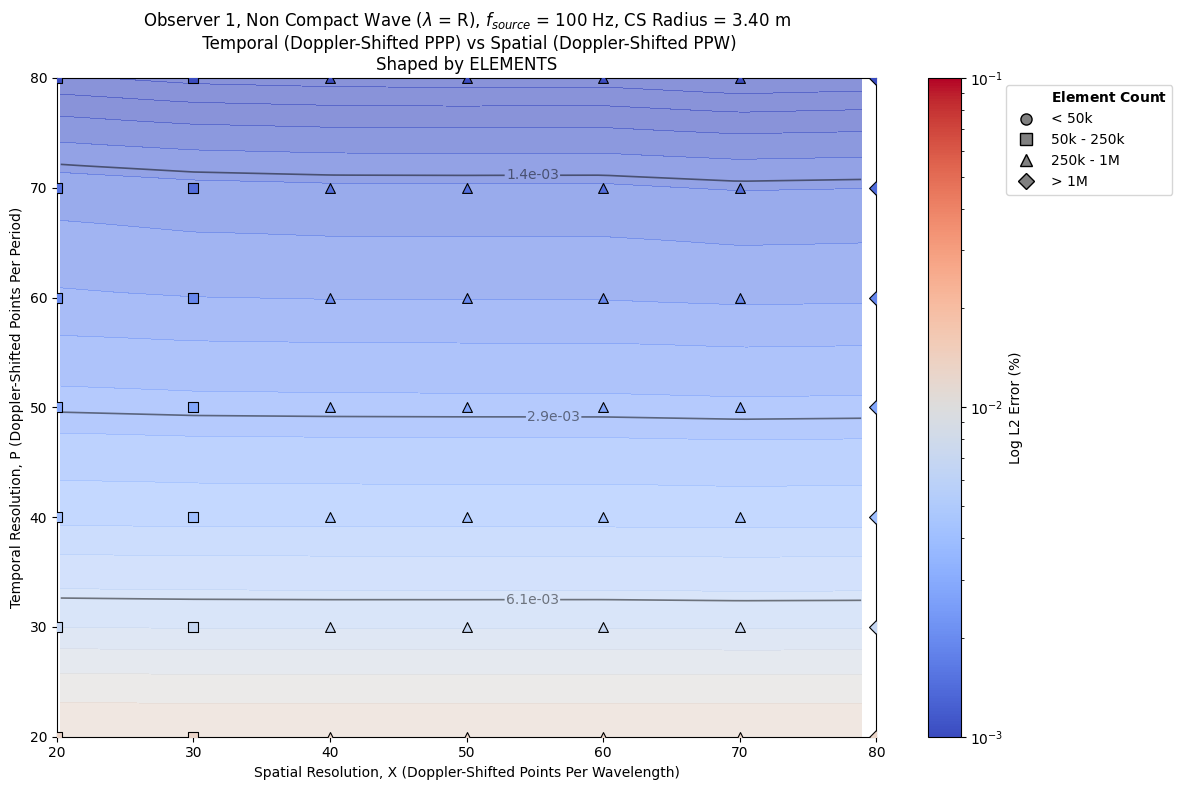

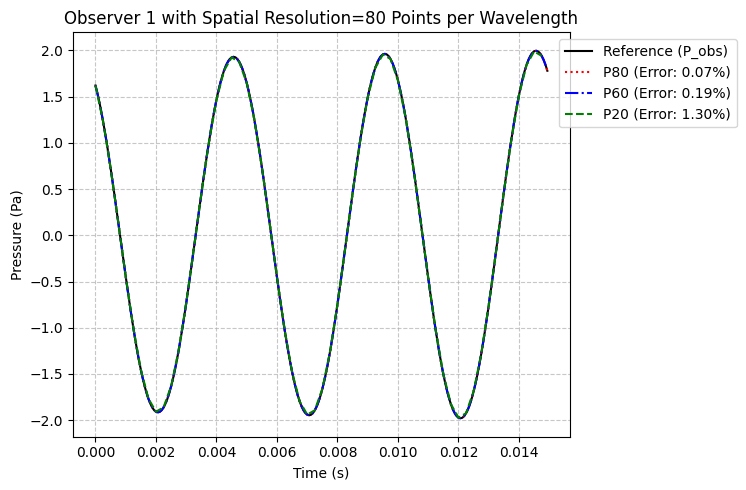

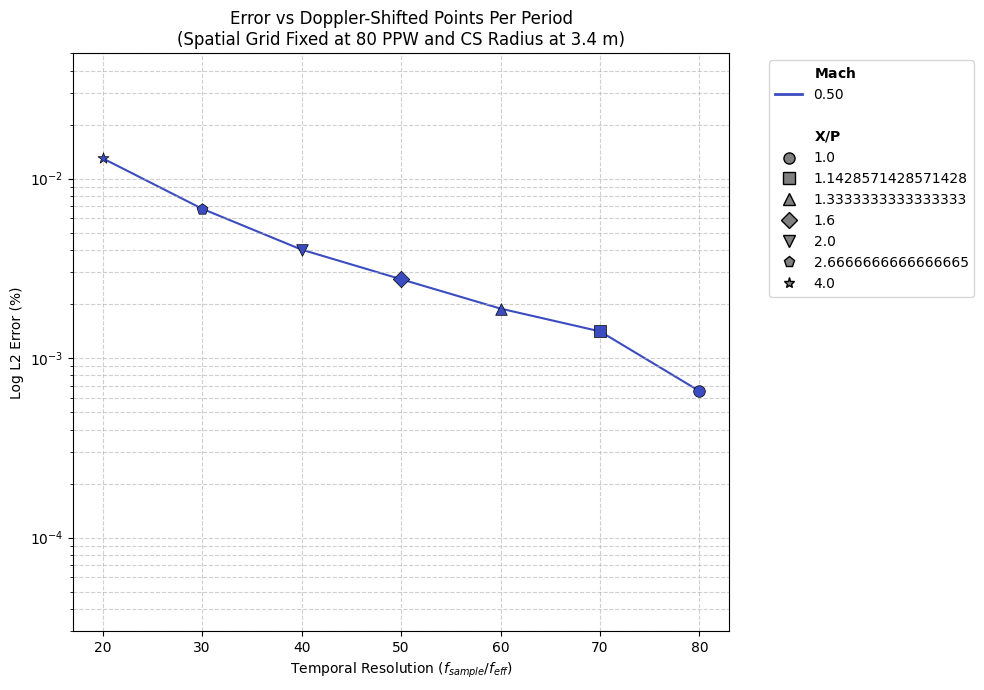

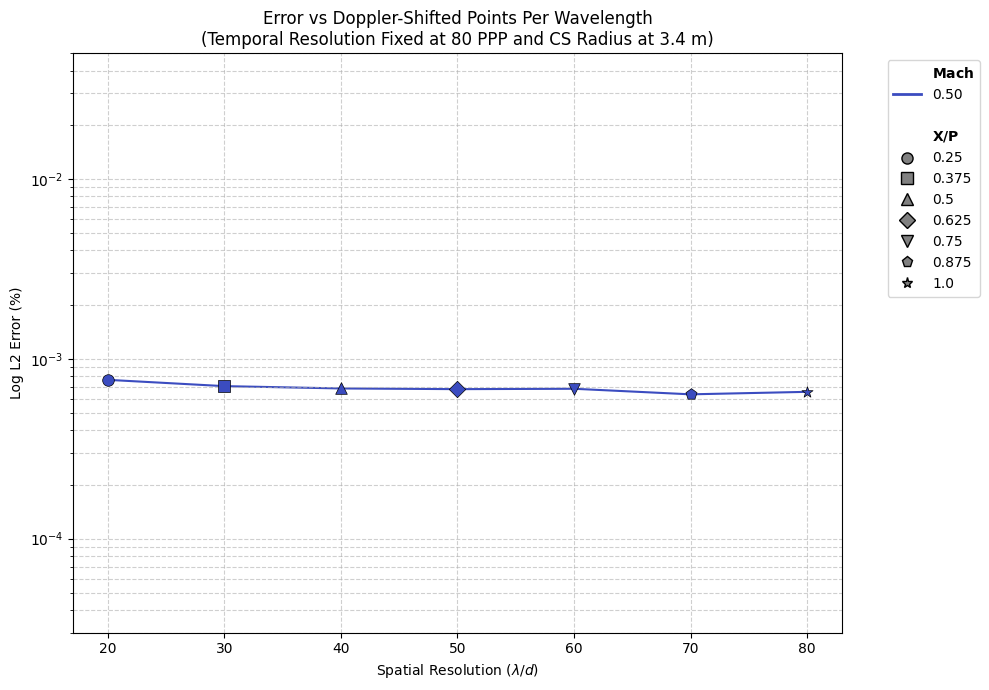

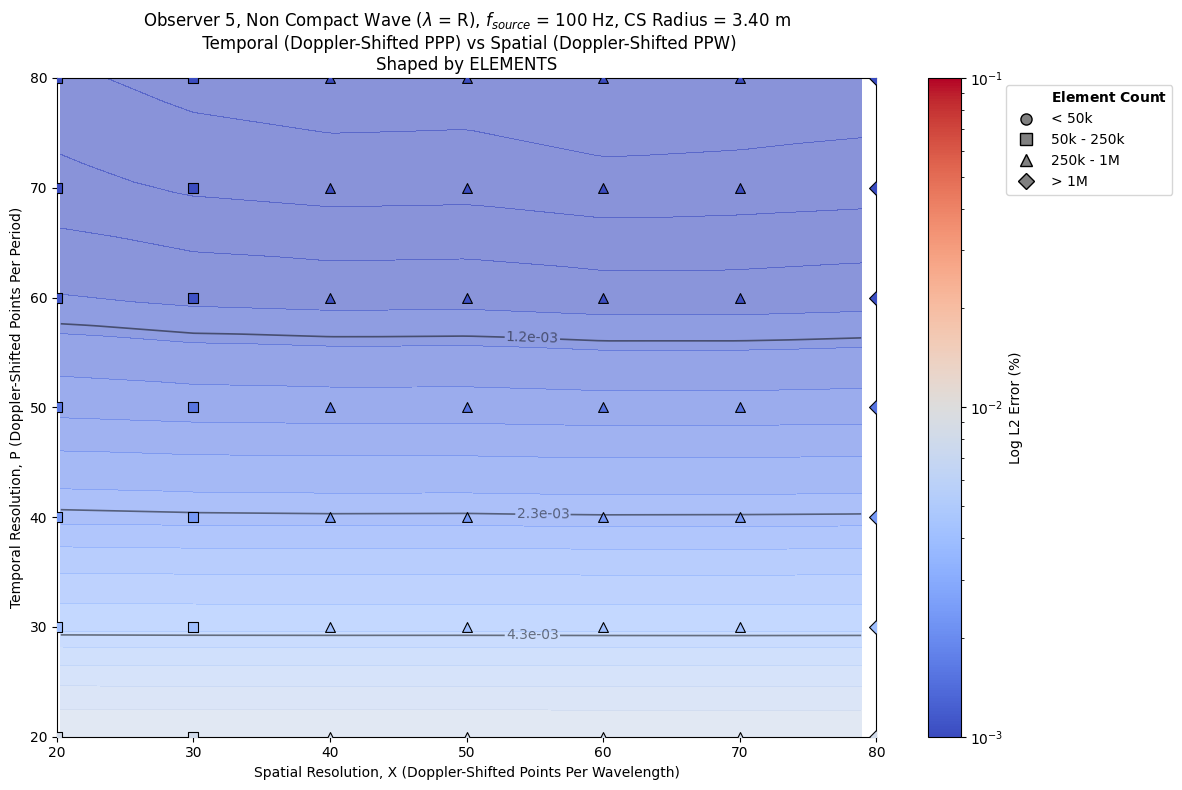

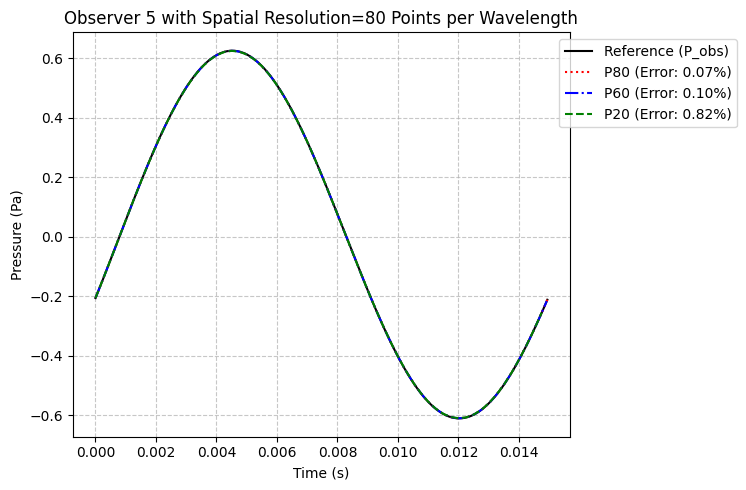

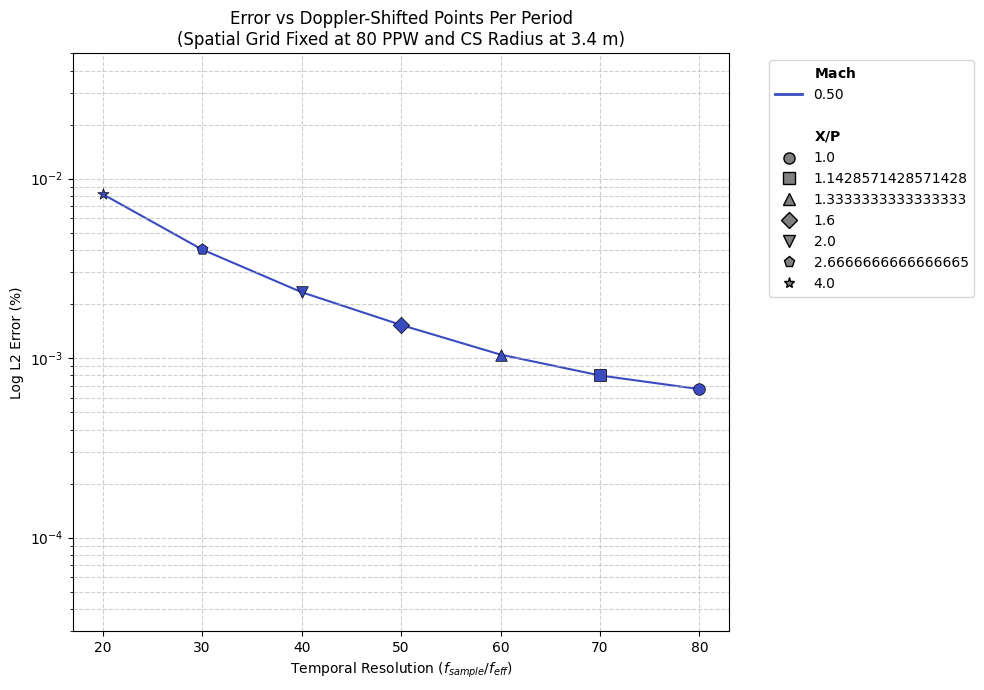

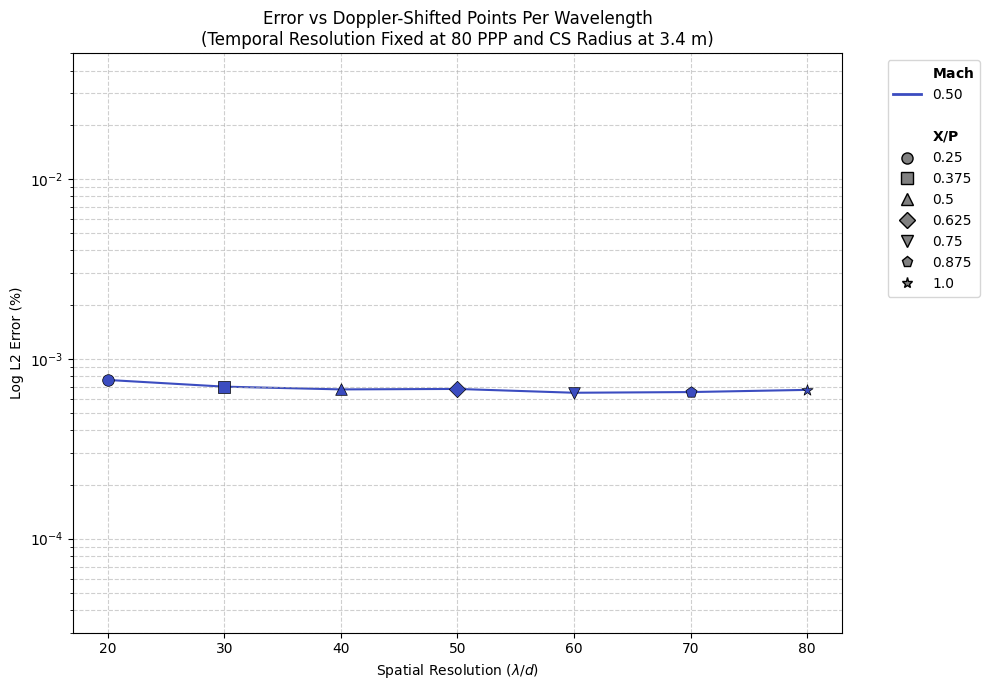

/tmp/ipykernel_212557/1567178829.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='batch_name', y='error', palette='coolwarm',


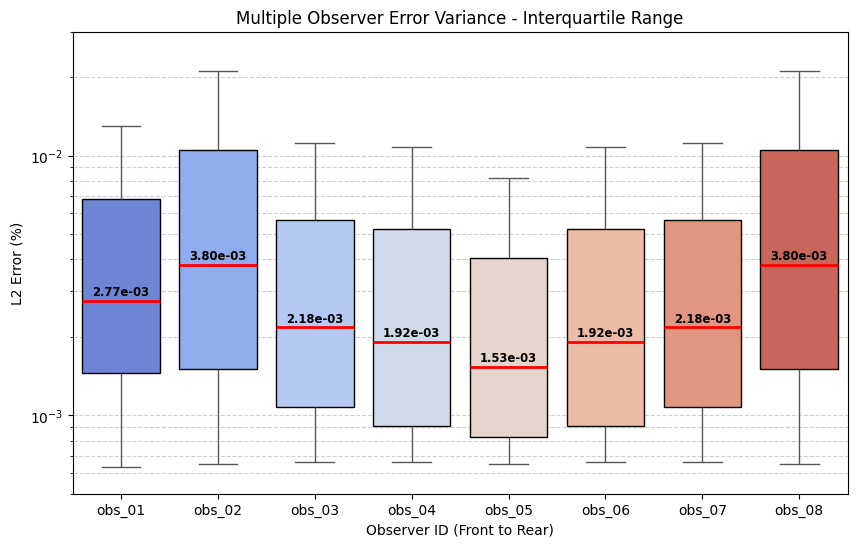

,mach,cfl,dt,P,X,error,elements,batch_name
0,0.5,1.666667,0.000167,29.999999,49.999999,0.006809,394384,obs_01
1,0.5,1.600000,0.000100,50.000000,80.000000,0.002750,1010025,obs_01
2,0.5,1.142857,0.000071,70.000000,80.000000,0.001409,1010025,obs_01
3,0.5,2.500000,0.000250,20.000000,50.000000,0.012982,394384,obs_01
4,0.5,0.666667,0.000167,29.999999,20.000000,0.006853,63001,obs_01
...,...,...,...,...,...,...,...,...
387,0.5,0.250000,0.000063,80.000000,20.000000,0.000766,63001,obs_08
388,0.5,0.500000,0.000125,40.000000,20.000000,0.006021,63001,obs_08
389,0.5,0.500000,0.000083,60.000000,30.000000,0.002366,142129,obs_08
390,0.5,3.000000,0.000250,20.000000,60.000000,0.021116,568516,obs_08


In [2]:
### Moving Monopole, Multiple Observers, R/lambda = 1 ###
FWHDataset.F_SOURCE = 100
FWHDataset.OMEGA = 2 * np.pi * FWHDataset.F_SOURCE
FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE
FWHDataset.R = FWHDataset.LAMBDA_SOURCE

folders = [
    'data_260615/multi_mono_50M_100hz/obs_01',
    'data_260615/multi_mono_50M_100hz/obs_02',
    'data_260615/multi_mono_50M_100hz/obs_03',
    'data_260615/multi_mono_50M_100hz/obs_04',
    'data_260615/multi_mono_50M_100hz/obs_05',
    'data_260615/multi_mono_50M_100hz/obs_06',
    'data_260615/multi_mono_50M_100hz/obs_07',
    'data_260615/multi_mono_50M_100hz/obs_08',
]

obs = [0, 4]
for i in obs:
    filepath = Path(folders[i])
    data = FWHDataset.compile_fwh_batch(filepath)
    analytical = FWHDataset(filepath / 'ana_M50.dat')
    title = f"Observer {i+1}, Non Compact Wave ($\lambda $ = R), $f_{{source}}$ = {FWHDataset.F_SOURCE} Hz, CS Radius = {FWHDataset.R:.2f} m"

    # FWHPlotter.plot_px_parameter_space(data, use_doppler=True, legend=True,
    #                                 add_title=title)

    FWHPlotter.plot_px_contour_space(data, use_doppler=True, add_title=title)
    
    FWHPlotter.plot_pressure(analytical, 
                            FWHDataset(filepath / "P80_X80_M50.dat"), 
                            FWHDataset(filepath / "P60_X80_M50.dat"),
                            FWHDataset(filepath / "P20_X80_M50.dat"),
                            ref_col='P_obs',
                            labels=['P80','P60','P20'],
                            title=f'Observer {i+1} with Spatial Resolution=80 Points per Wavelength')

    FWHPlotter.plot_cfl_convergence_by_mach(filepath, 'dt', analytical, [80, FWHDataset.R], use_doppler=True, legend=True)
    FWHPlotter.plot_cfl_convergence_by_mach(filepath, 'dx', analytical, [80, FWHDataset.R], use_doppler=True, legend=True)

box_plotter(folders)

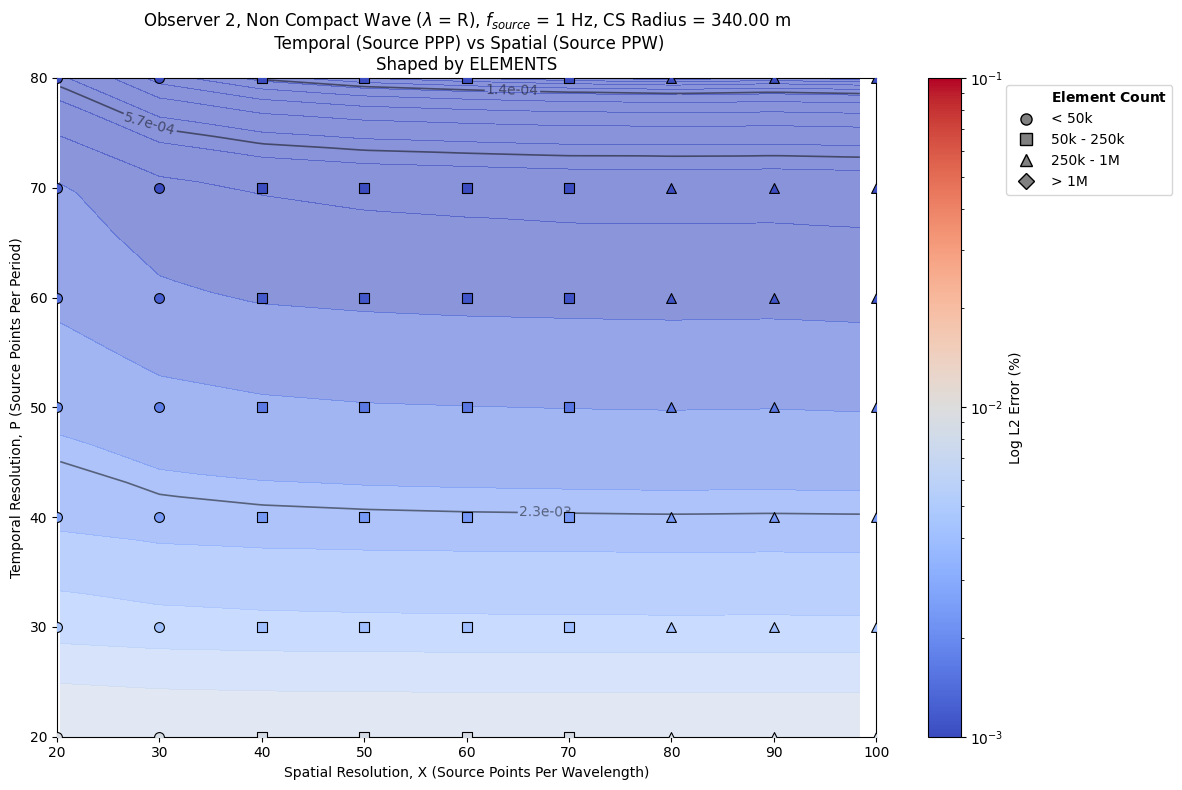

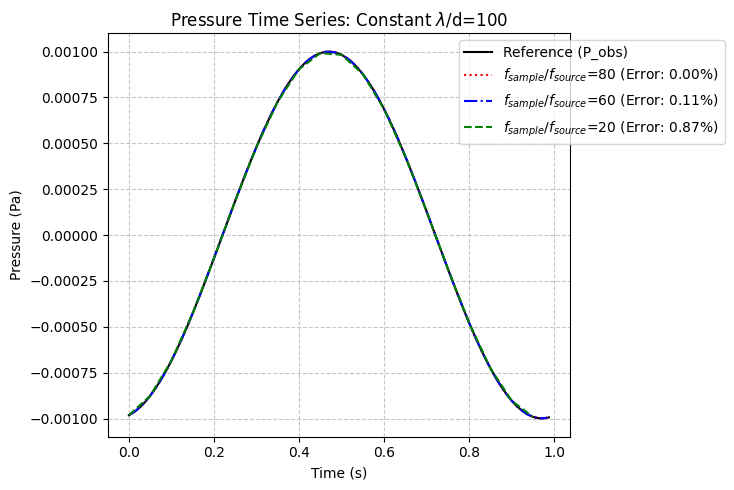

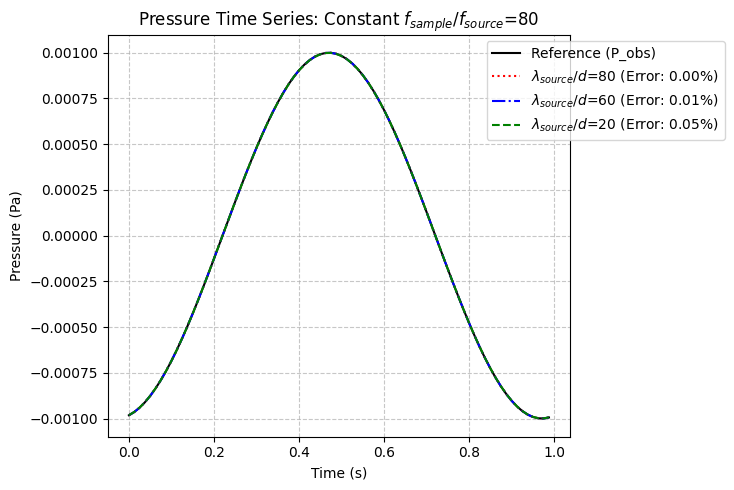

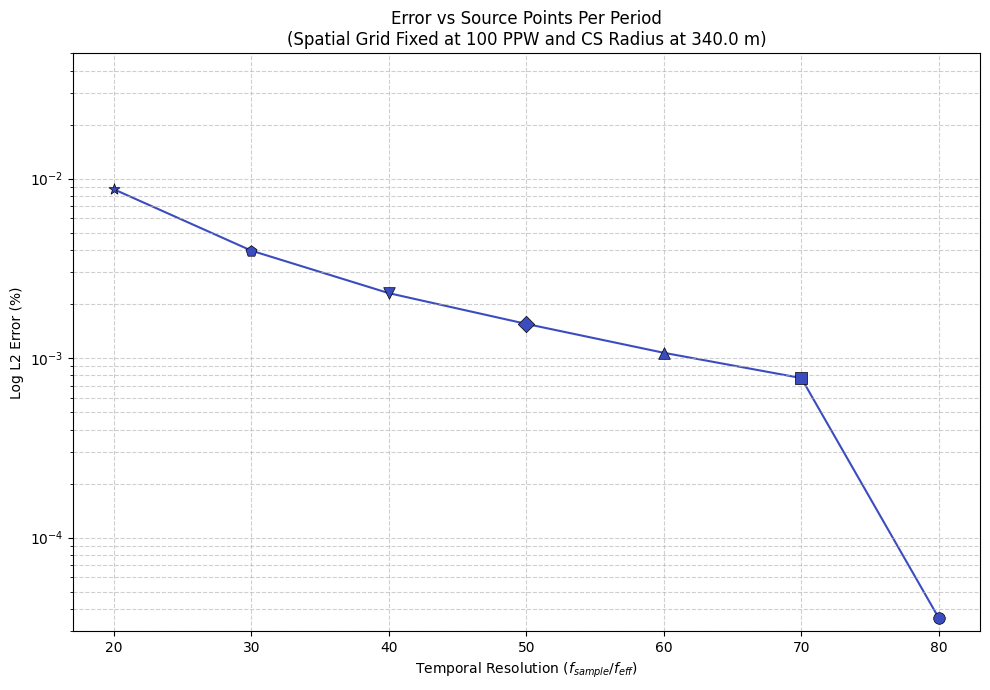

In [4]:
### Stationary Single Monopole, Non Compact 100 Hz ###
# FWHDataset.OMEGA = 10.0
FWHDataset.F_SOURCE = 1
FWHDataset.OMEGA = 2 * np.pi * FWHDataset.F_SOURCE
FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE
FWHDataset.R = FWHDataset.LAMBDA_SOURCE

filepath = Path('data_260615/single_mono_stationary_noncompact_1hz/')
data = FWHDataset.compile_fwh_batch(filepath)
analytical = FWHDataset(filepath / 'ana_M00.dat')

# FWHPlotter.plot_px_parameter_space(data, use_doppler=False, legend=True,
#                                    add_title=f"Non Compact Wave ($\lambda $ = R) F_{{source}} = {FWHDataset.F_SOURCE} Hz, CS Radius = {FWHDataset.R:.2f} m")
title = f"Observer 2, Non Compact Wave ($\lambda $ = R), $f_{{source}}$ = {FWHDataset.F_SOURCE} Hz, CS Radius = {FWHDataset.R:.2f} m"

FWHPlotter.plot_px_contour_space(data, add_title=title, use_doppler=False)

FWHPlotter.plot_pressure(analytical, 
                         FWHDataset(filepath / "P80_X100_M00.dat"), 
                         FWHDataset(filepath / "P60_X100_M00.dat"),
                         FWHDataset(filepath / "P20_X100_M00.dat"),
                         ref_col='P_obs',
                         labels=[f'$f_{{sample}}/f_{{source}}$=80',
                                 '$f_{{sample}}/f_{{source}}$=60',
                                 '$f_{{sample}}/f_{{source}}$=20'],
                        title=f'Pressure Time Series: Constant $\lambda$/d=100')

FWHPlotter.plot_pressure(analytical, 
                         FWHDataset(filepath / "P80_X100_M00.dat"), 
                         FWHDataset(filepath / "P80_X50_M00.dat"),
                         FWHDataset(filepath / "P80_X20_M00.dat"),
                         ref_col='P_obs',
                         labels=[f'$\lambda_{{source}}/d$=80',
                                 '$\lambda_{{source}}/d$=60',
                                 '$\lambda_{{source}}/d$=20'],
                        title=f"Pressure Time Series: Constant $f_{{sample}}/f_{{source}}$=80")

FWHPlotter.plot_cfl_convergence_by_mach(filepath, 'dt', analytical, [100, FWHDataset.R], use_doppler=False, legend=False)

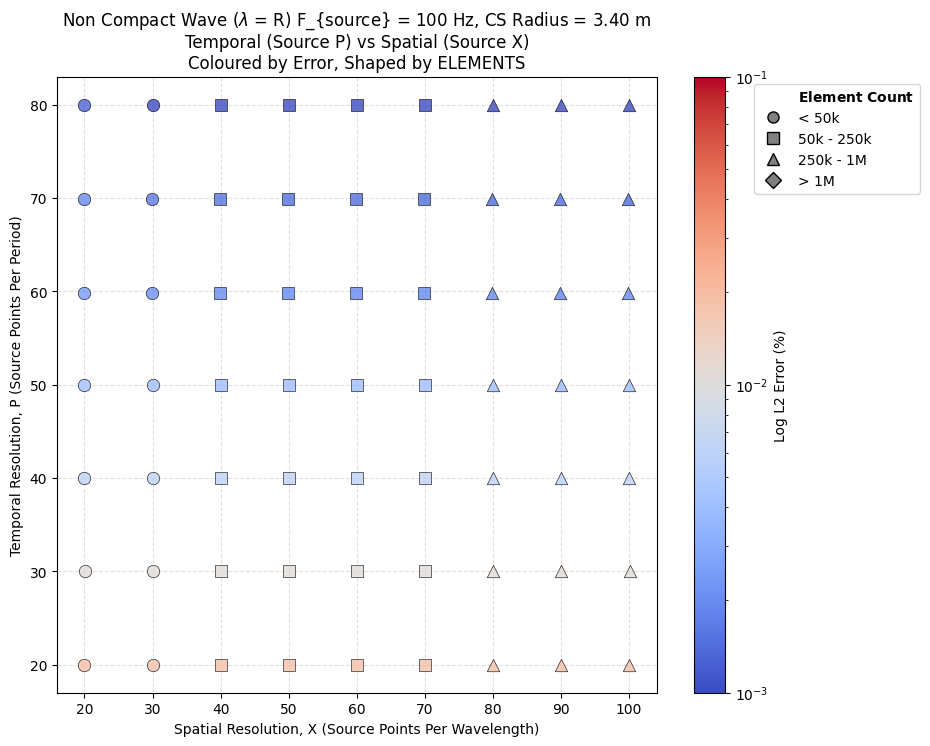

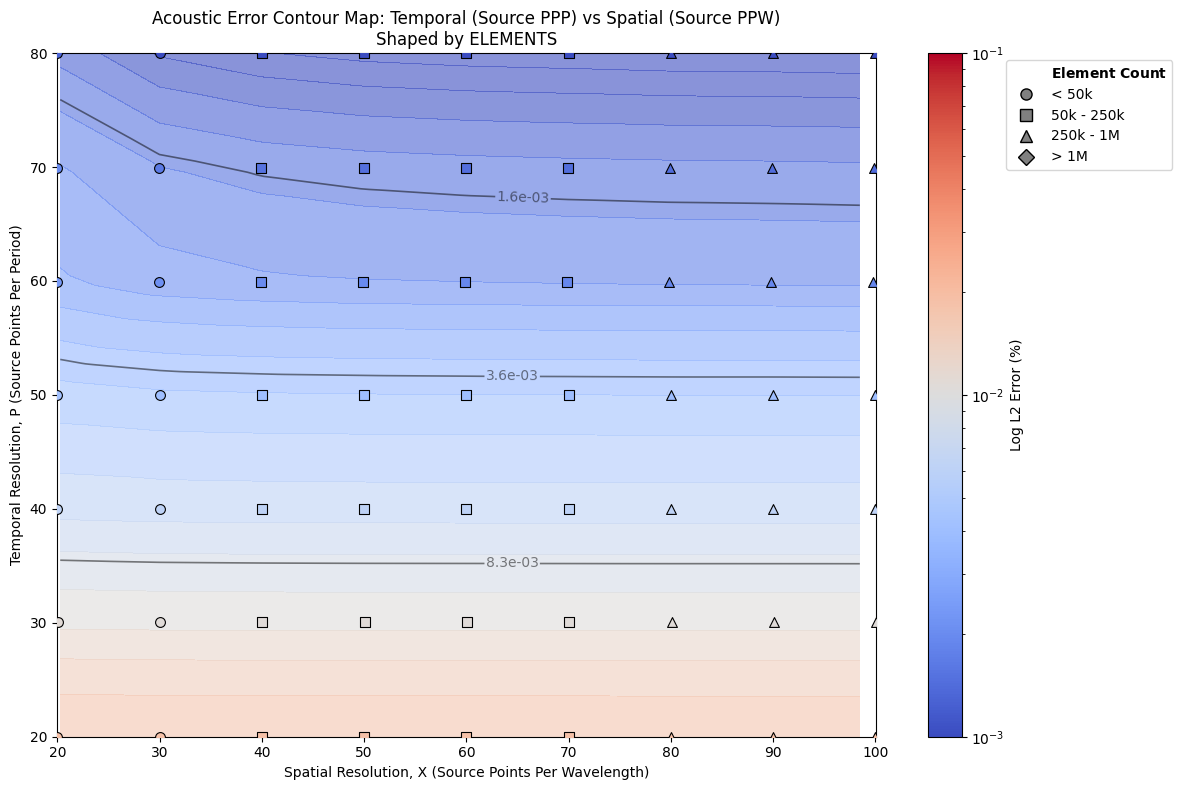

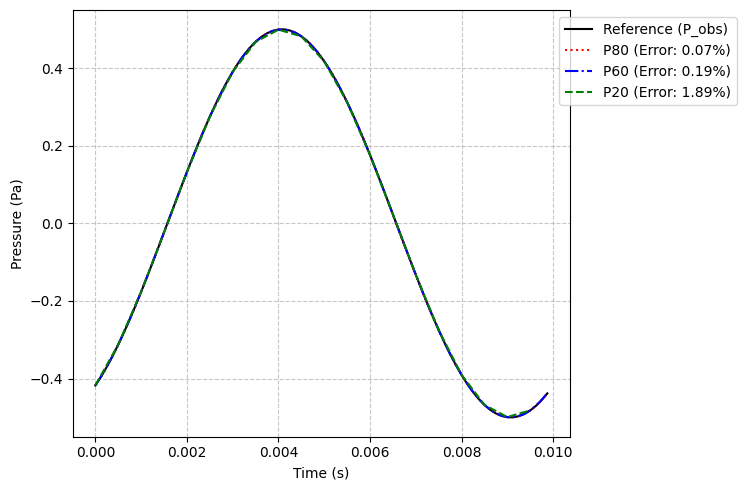

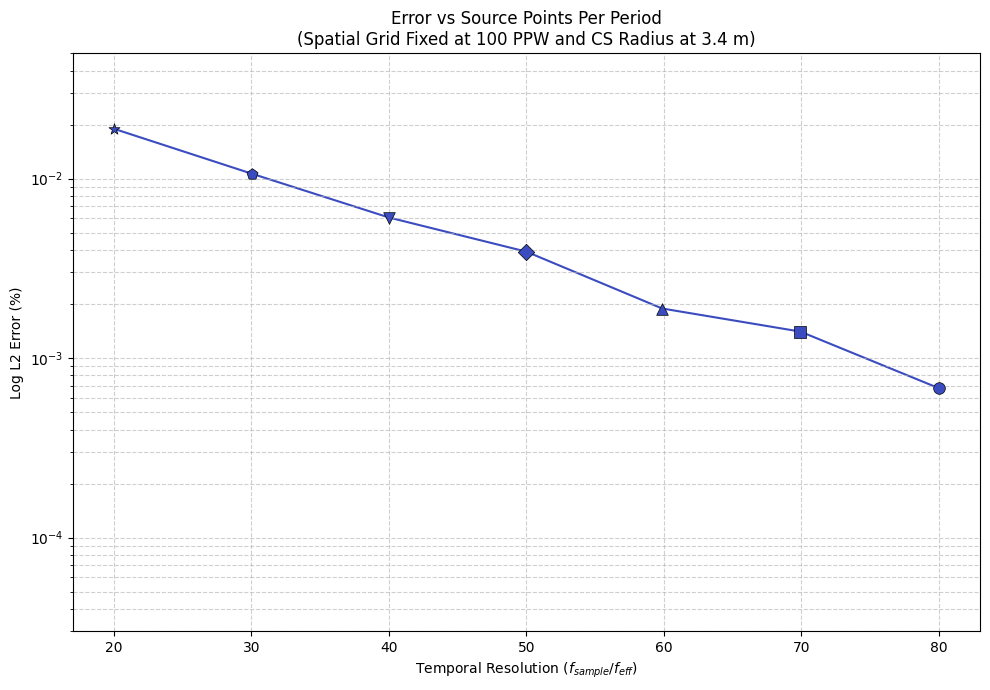

In [8]:
### Stationary Single Monopole, Non Compact 100 Hz ###
# FWHDataset.OMEGA = 10.0
FWHDataset.F_SOURCE = 100
FWHDataset.OMEGA = 2 * np.pi * FWHDataset.F_SOURCE
FWHDataset.LAMBDA_SOURCE = FWHDataset.C / FWHDataset.F_SOURCE
FWHDataset.R = FWHDataset.LAMBDA_SOURCE

filepath = Path('data_260615/single_mono_stationary_noncompact_100hz/')
data = FWHDataset.compile_fwh_batch(filepath)
analytical = FWHDataset(filepath / 'ana_M00.dat')

FWHPlotter.plot_px_parameter_space(data, use_doppler=False, legend=True,
                                   add_title=f"Non Compact Wave ($\lambda $ = R) F_{{source}} = {FWHDataset.F_SOURCE} Hz, CS Radius = {FWHDataset.R:.2f} m")
FWHPlotter.plot_px_contour_space(data, False)

FWHPlotter.plot_pressure(analytical, 
                         FWHDataset(filepath / "P80_X100_M00.dat"), 
                         FWHDataset(filepath / "P60_X100_M00.dat"),
                         FWHDataset(filepath / "P20_X100_M00.dat"),
                         ref_col='P_obs',
                         labels=['P80','P60','P20'])

FWHPlotter.plot_cfl_convergence_by_mach(filepath, 'dt', analytical, [100, FWHDataset.R], use_doppler=False, legend=False)

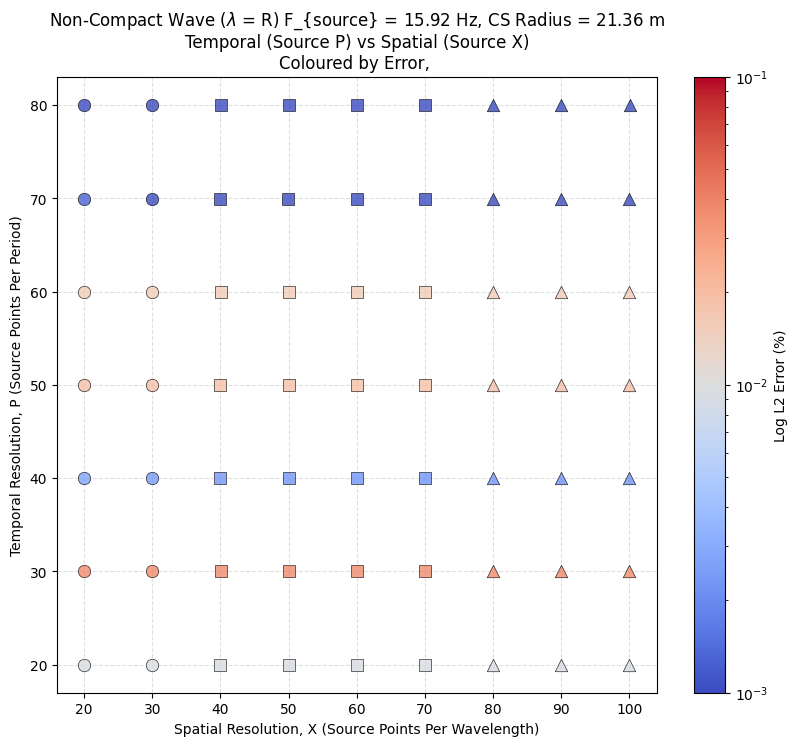

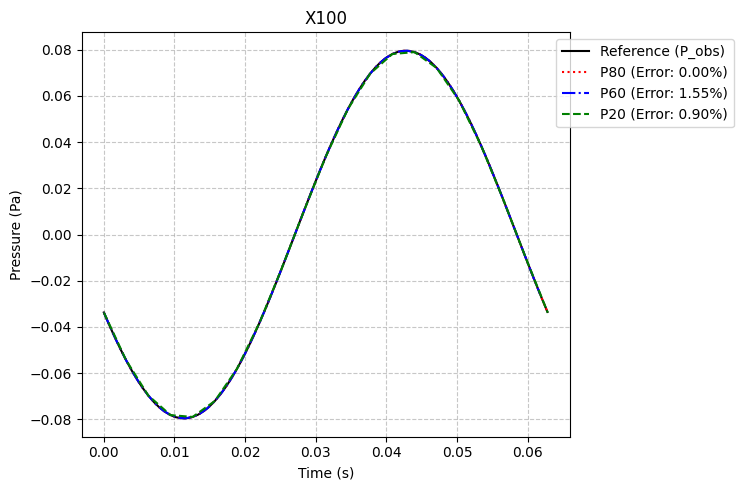

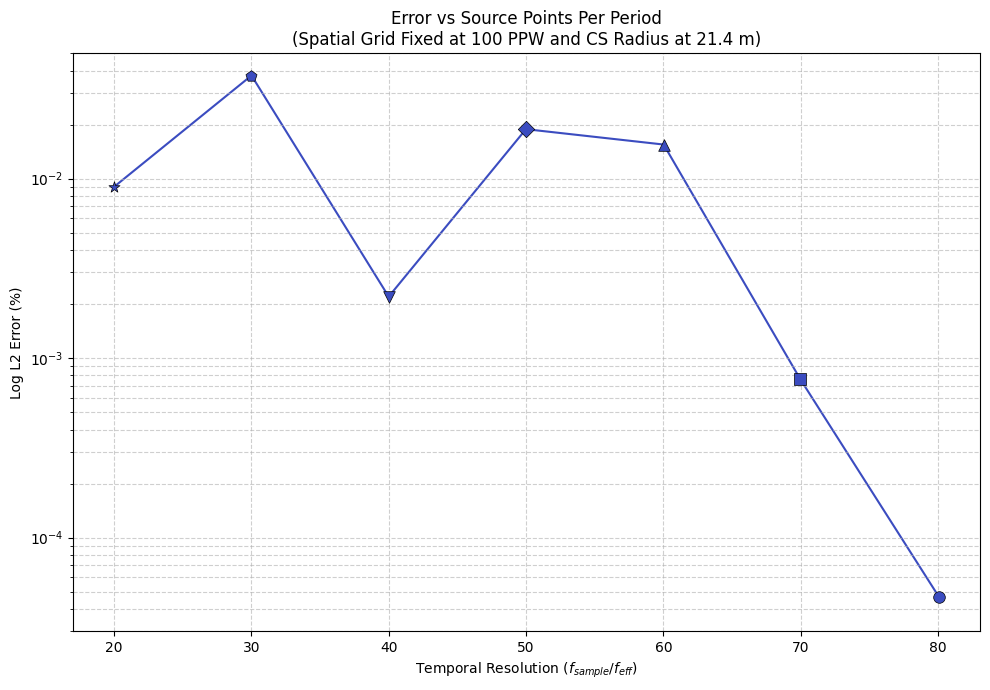

In [3]:
### Stationary Single Monopole, Non Compact 10 rad/s ###
# FWHDataset.OMEGA = 10.0
# FWHDataset.F_SOURCE = 100
FWHDataset.OMEGA = 100
FWHDataset.F_SOURCE = FWHDataset.OMEGA / (2 * np.pi) 
FWHDataset.LAMBDA_SOURCE = 340.0 / FWHDataset.F_SOURCE
FWHDataset.R = FWHDataset.LAMBDA_SOURCE

filepath = Path('data_260615/single_mono_stationary_noncompact_100rads/')
data = FWHDataset.compile_fwh_batch(filepath)
analytical = FWHDataset(filepath / 'ana_M00.dat')

FWHPlotter.plot_px_parameter_space(data, use_doppler=False, legend=False,
                                   add_title=f"Non-Compact Wave ($\lambda $ = R) F_{{source}} = {FWHDataset.F_SOURCE:.2f} Hz, CS Radius = {FWHDataset.R:.2f} m")

FWHPlotter.plot_pressure(analytical,
                         FWHDataset(filepath / "P80_X100_M00.dat"), 
                         FWHDataset(filepath / "P60_X100_M00.dat"),
                         FWHDataset(filepath / "P20_X100_M00.dat"),
                         ref_col='P_obs',
                         labels=['P80','P60','P20'], title='X100')

FWHPlotter.plot_cfl_convergence_by_mach(filepath, 'dt', analytical, [100, FWHDataset.R], use_doppler=False, legend=False)

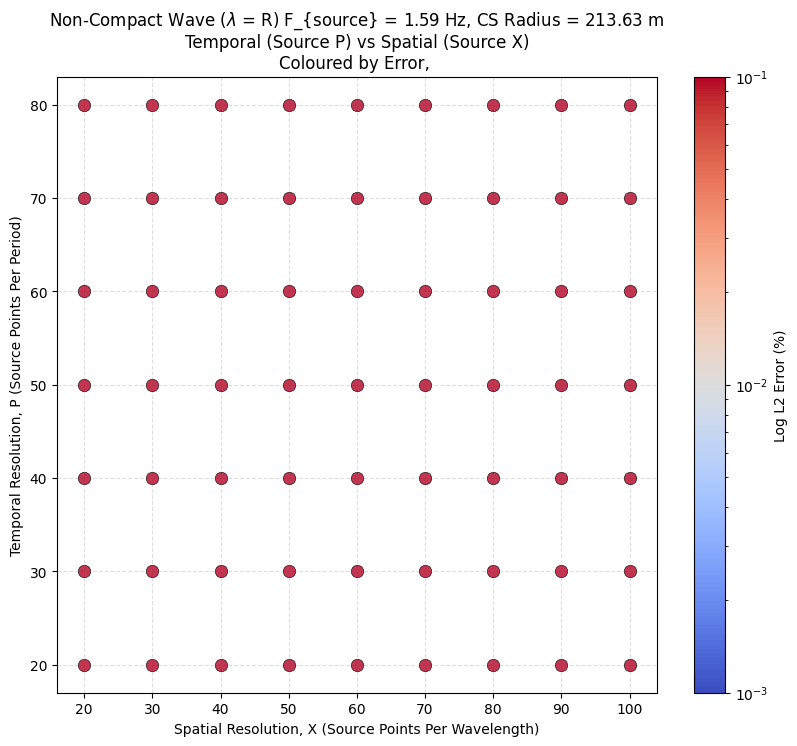

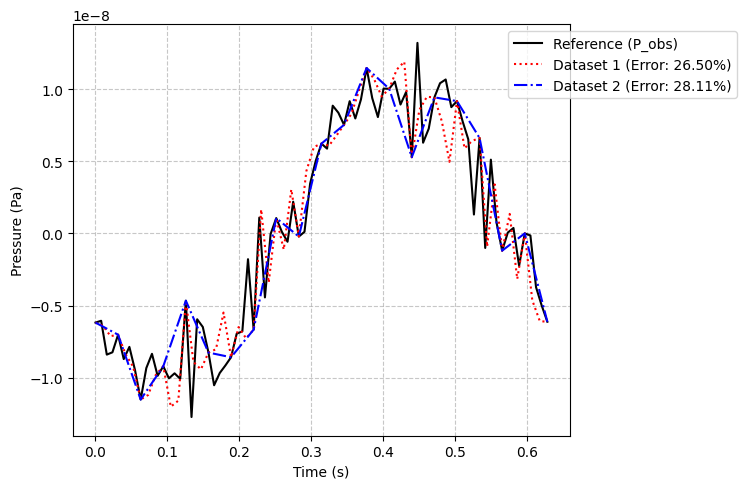

213.62830044410592


In [9]:
### Stationary Single Monopole, Non Compact 10 rad/s ###
# FWHDataset.OMEGA = 10.0
# FWHDataset.F_SOURCE = 100
FWHDataset.OMEGA = 10
FWHDataset.F_SOURCE = FWHDataset.OMEGA / (2 * np.pi) 
FWHDataset.LAMBDA_SOURCE = 340.0 / FWHDataset.F_SOURCE
FWHDataset.R = FWHDataset.LAMBDA_SOURCE

filepath = Path('data_260615/single_mono_stationary_noncompact_10rads/')
data = FWHDataset.compile_fwh_batch(filepath)
analytical = FWHDataset(filepath / 'ana_M00.dat')

FWHPlotter.plot_px_parameter_space(data, use_doppler=False, legend=False,
                                   add_title=f"Non-Compact Wave ($\lambda $ = R) F_{{source}} = {FWHDataset.F_SOURCE:.2f} Hz, CS Radius = {FWHDataset.R:.2f} m")

FWHPlotter.plot_pressure(
                         FWHDataset(filepath / "P80_X100_M00.dat"), 
                         FWHDataset(filepath / "P60_X100_M00.dat"),
                         FWHDataset(filepath / "P20_X100_M00.dat"),
                         ref_col='P_obs',
                         labels=['P80','P60','P20'])
print(FWHDataset.LAMBDA_SOURCE)

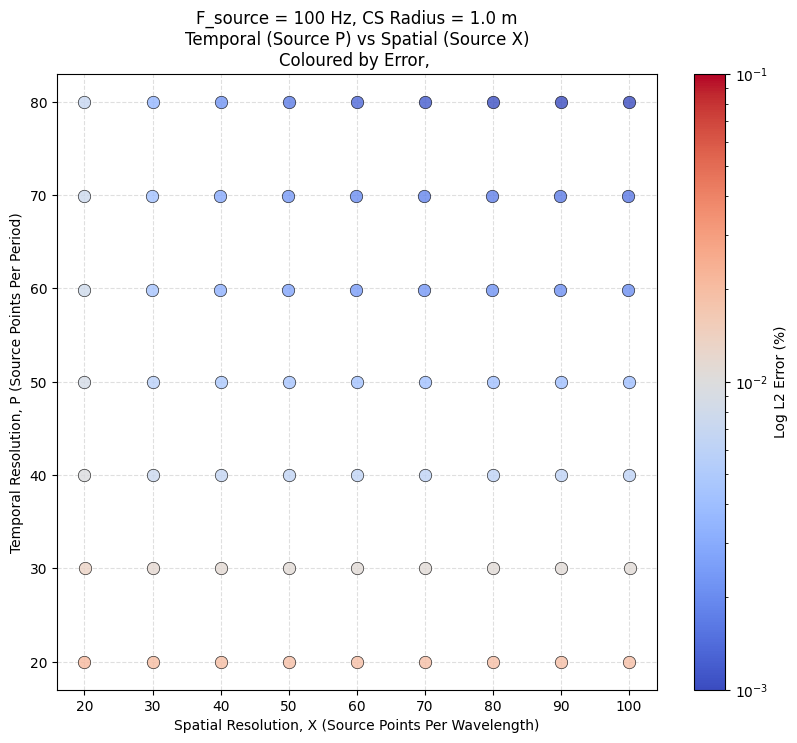

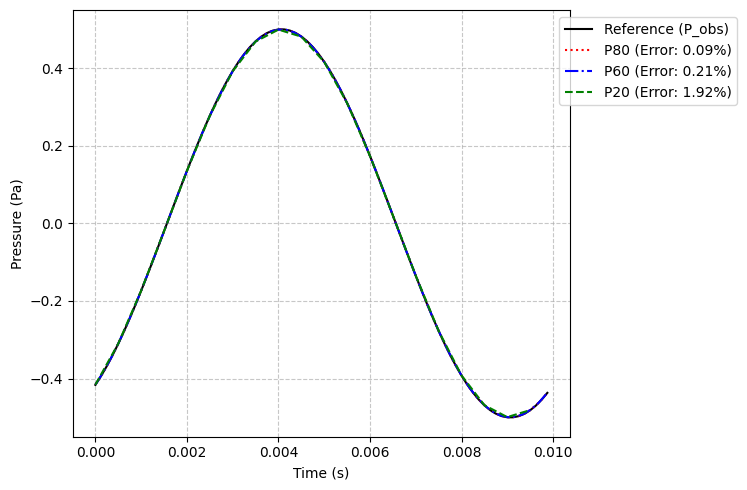

In [25]:
### Stationary Single Monopole, 100 Hz ###
# Setup
FWHDataset.OMEGA = 2 * np.pi * 100.0
FWHDataset.F_SOURCE = 100.0
FWHDataset.LAMBDA_SOURCE = 340.0 / FWHDataset.F_SOURCE
FWHDataset.R = 1.0

filepath = Path('data_260615/single_mono_stationary_R1_F100/')
data = FWHDataset.compile_fwh_batch(filepath)
analytical = FWHDataset(filepath / 'ana_M00.dat')

FWHPlotter.plot_px_parameter_space(data, use_doppler=False, legend=False,
                                   add_title="F_source = 100 Hz, CS Radius = 1.0 m")

FWHPlotter.plot_pressure(analytical, 
                         FWHDataset(filepath / "P80_X100_M00.dat"), 
                         FWHDataset(filepath / "P60_X100_M00.dat"),
                         FWHDataset(filepath / "P20_X100_M00.dat"),
                         ref_col='P_obs',
                         labels=['P80','P60','P20'])

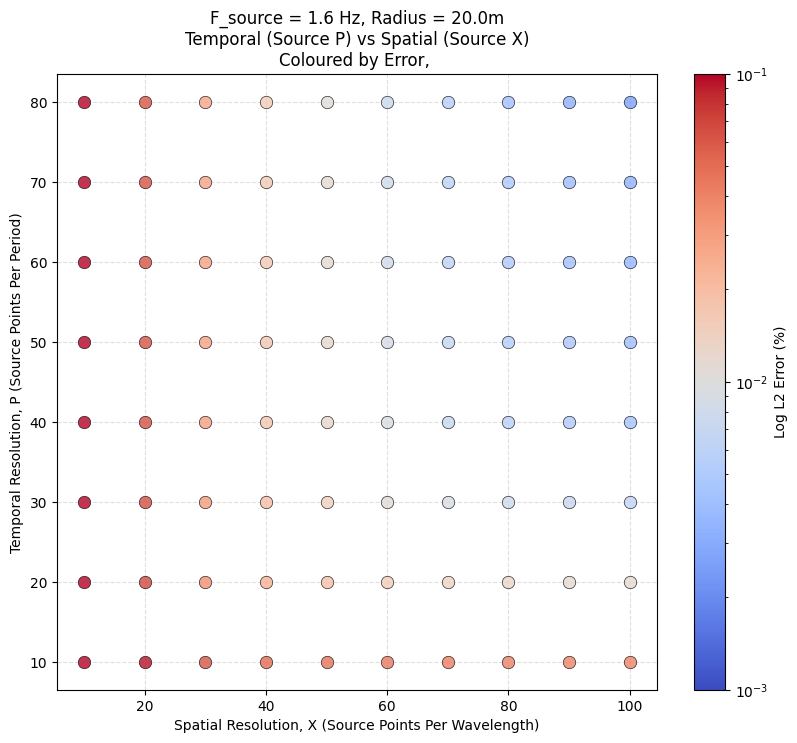

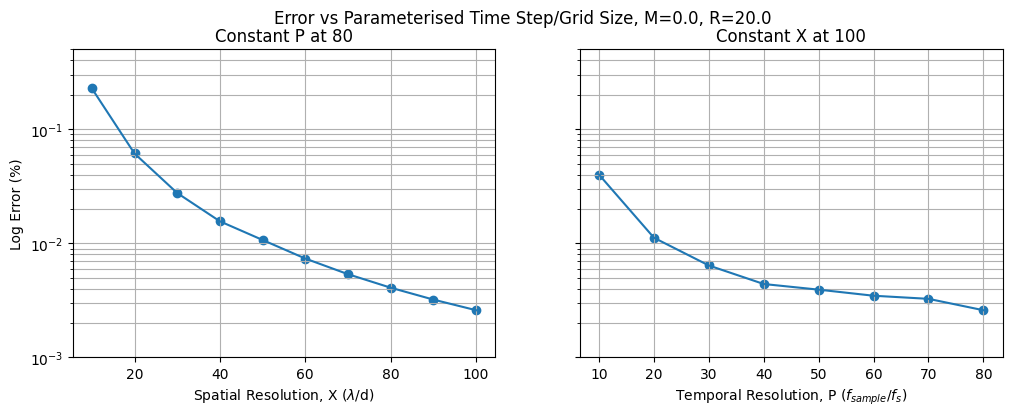

In [5]:
#### Stationary Single Monopole ####
# Setup
filepath = Path('data_260610/single_mono/')
data_m00 = FWHDataset.compile_fwh_batch(filepath)
analytical = FWHDataset(filepath / 'ana_M00.dat')

df_00 = pd.DataFrame(data_m00)
df_00['X'] = df_00['X'].round()
df_00['P'] = df_00['P'].round()

# X vs P Matrix
FWHPlotter.plot_px_parameter_space(data_m00, use_doppler=False, legend=False,
                                   add_title="F_source = 1.6 Hz, Radius = 20.0m")

# Line Plot P vs Error, X vs Error
line_plot(df_00, 80, 100)

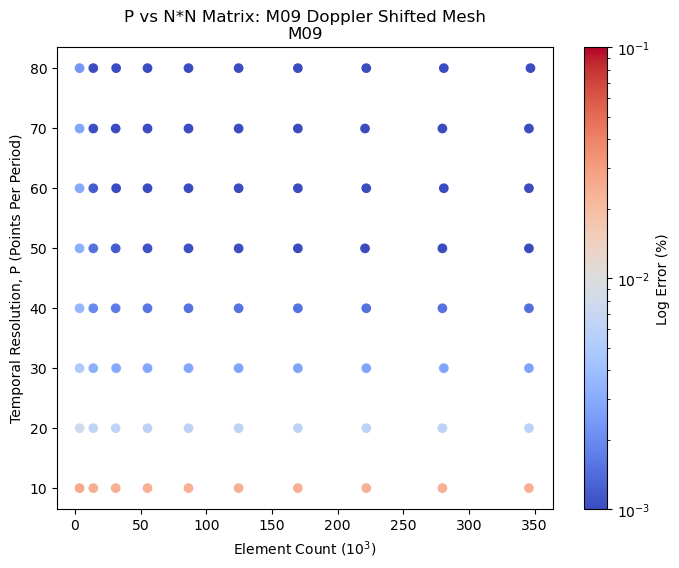

In [35]:
df_M09 = pd.DataFrame(FWHDataset.compile_fwh_batch('data_260603/test_M09', use_doppler=True))
p_element_plot(df_M09,
               title='P vs N*N Matrix: M09 Doppler Shifted Mesh\nM09')

In [ ]:
df_M00 = pd.DataFrame(FWHDataset.compile_fwh_batch(Path("data_260610/single_mono")))

df_M00.sort_values(by=['error'], ascending=False)


In [ ]:
FWHPlotter.plot_px_contour_space(df_M00, use_doppler=False)

In [ ]:
df_M0905 = pd.DataFrame(FWHDataset.compile_fwh_batch("data_260609/test_M09_M05_mesh", use_doppler=True))
p_element_plot(df_M0905,
               title='P vs N*N Matrix: M05 Doppler Shifted Mesh\n M09')

In [ ]:
df_M09nd = pd.DataFrame(FWHDataset.compile_fwh_batch('data_260609/test_M09_non_doppler_mesh', use_doppler=False))
p_element_plot(df_M09nd, 
               title='P vs N*N Matrix: Freestream Wavelength Mesh\n M09')

In [ ]:
filepath = Path('data_260609/test_M09_non_doppler_mesh/')
ana = FWHDataset(filepath / 'ana_M90.dat')
p80_x100 = FWHDataset(filepath / 'P80_X100_M90.dat')
p40_x100 = FWHDataset(filepath / 'P40_X100_M90.dat')
p10_x100 = FWHDataset(filepath / 'P10_X100_M90.dat')

FWHPlotter.plot_pressure(ana, p80_x100, p40_x100, p10_x100, ref_col='P_obs', labels=[
    'P80, X100, f_sample = 1273 Hz, grid_count = 3481',
    'P40, X100, f_sample = 63.7 Hz, grid_count = 3481',
    'P10, X100, f_sample = 15.9 Hz, grid_count = 3481'
],
title="Non-Doppler Shifted Spatial and Temporal Resolutions\nM=0.9, fsource=1.6 Hz, Doppler f=16 Hz")

In [ ]:
p80_x50 = FWHDataset(filepath / 'P80_X50_M90.dat')
p80_x10 = FWHDataset(filepath / 'P80_X10_M90.dat')

FWHPlotter.plot_pressure(ana, p80_x100, p80_x50, p80_x10, ref_col='P_obs', labels=[
    'P80, X100, f_sample = 1273 Hz, grid_count = 3481',
    'P80, X50, f_sample = 1273 Hz, grid_count = 841',
    'P80, X10, f_sample = 1273 Hz, grid_count = 36'
], title="Non-Doppler Shifted Spatial and Temporal Resolutions\n" \
"M=0.9, lambda_source=213 m, Doppler Lambda=21.3 m"
)

/tmp/ipykernel_155174/1115765663.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='batch_name', y='error', palette='coolwarm',


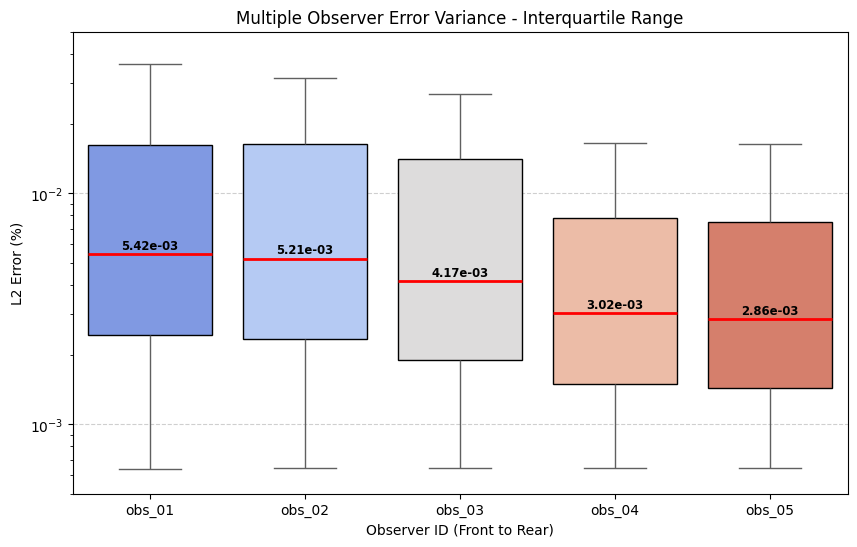

In [8]:
folders = [
    'data_260609/multi_obs/obs_01',
    'data_260609/multi_obs/obs_02',
    'data_260609/multi_obs/obs_03',
    'data_260609/multi_obs/obs_04',
    'data_260609/multi_obs/obs_05',
]

master = []
for folder in folders:
    master.extend(FWHDataset.compile_fwh_batch(folder, use_doppler=True))

df = pd.DataFrame(master)
obs_01 = df[df['batch_name']=='obs_01']
obs_02 = df[df['batch_name']=='obs_02']
obs_03 = df[df['batch_name']=='obs_03']
obs_04 = df[df['batch_name']=='obs_04']
obs_05 = df[df['batch_name']=='obs_05']

fig, ax = plt.subplots(figsize=(10, 6))

# 1. Create the Box Plot
# showfliers=True #keeps the outlier dots visible (your coarse grid runs)
sns.boxplot(data=df, x='batch_name', y='error', palette='coolwarm', 
            boxprops=dict(edgecolor='black'), medianprops=dict(color='red', linewidth=2),
            showfliers=False, ax=ax)

medians = df.groupby('batch_name')['error'].median()
obs_names = ['obs_01', 'obs_02', 'obs_03', 'obs_04', 'obs_05']

for i, obs in enumerate(obs_names):
    median_val = medians[obs]
    text_label = f"{median_val:.2e}" 
    ax.text(i, median_val * 1.05, text_label, 
            horizontalalignment='center', size='small', color='black', weight='bold')

ax.set_yscale('log')
ax.set_ylabel('L2 Error (%)')
ax.set_ylim(5e-4, 5e-2)
ax.set_xlabel('Observer ID (Front to Rear)')
ax.set_title('Multiple Observer Error Variance - Interquartile Range')
ax.grid(True, axis='y', linestyle='--', alpha=0.6)

plt.show()

In [ ]:
print("All mean:", df['error'].mean(), "All median:", df['error'].median())

In [ ]:
medians = [
    obs_01['error'].median(),
    obs_02['error'].median(),
    obs_03['error'].median(),
    obs_04['error'].median(),
    obs_05['error'].median(),
]
std_dev = [
    obs_01['error'].std(),
    obs_02['error'].std(),
    obs_03['error'].std(),
    obs_04['error'].std(),
    obs_05['error'].std(),
]
maxs = [
    obs_01['error'].max(),
    obs_02['error'].max(),
    obs_03['error'].max(),
    obs_04['error'].max(),
    obs_05['error'].max(),
]

mins = [
    obs_01['error'].min(),
    obs_02['error'].min(),
    obs_03['error'].min(),
    obs_04['error'].min(),
    obs_05['error'].min(),
]

means = [
    obs_01['error'].mean(),
    obs_02['error'].mean(),
    obs_03['error'].mean(),
    obs_04['error'].mean(),
    obs_05['error'].mean(),
]

labels = ['obs_01', 'obs_02', 'obs_03', 'obs_04', 'obs_05']

fig, ax = plt.subplots()
ax.bar(labels, medians, edgecolor='black', color='steelblue')
ax.errorbar(labels, medians, yerr=means, c='r')
ax.set_yscale('log')
ax.set_ylim(1e-3, 1e-1)
ax.set_ylabel('Median L2 Error (%)')
ax.grid(True, axis='y', ls='--', alpha=0.5)
ax.set_title("Multiple Observer Test - Median Error of Each Observer\n Errorbar: Std Dev")

plt.show()

In [ ]:
df.sort_values(by=['error','batch_name'], ascending=False).head(10)

In [ ]:
# import seaborn as sns
# import matplotlib.pyplot as plt
# import numpy as np

# fig, ax = plt.subplots(figsize=(8, 6))

# # estimator=np.median calculates the central tendency
# # errorbar='sd' draws the standard deviation lines to show variance across X and P
# sns.barplot(data=df, x='batch_name', y='error', estimator=np.median, 
#             errorbar='sd', palette='coolwarm', edgecolor='black', ax=ax)

# ax.set_yscale('log')
# ax.set_ylabel('Median L2 Error (%)')
# ax.set_xlabel('Observer')
# ax.set_title('Error Distribution Across Observer Arc')
# ax.grid(True, axis='y', linestyle='--', alpha=0.6)

# plt.show()

In [ ]:
# filepath = Path(f"{folders[0]}/")
# ana = FWHDataset(filepath / "ana_M50.dat")
# p10_x10 = FWHDataset(filepath / "P10_X10_M50.dat")
# p80_x100 = FWHDataset(filepath / "P80_X100_M50.dat")
# FWHPlotter.plot_pressure(ana, p10_x10, p80_x100, ref_col='P_obs')

In [ ]:
title = ['Observer 1 (100, 0, 0)', 
         'Observer 2 (70.7, 70.7, 0)', 
         'Observer 3 (0, 100, 0)', 
         'Observer 4 (-70.7, 70.7, 0)', 
         'Observer 5 (-100, 0, 0)']

for i,j in zip(folders, title):
    data = FWHDataset.compile_fwh_batch(Path(i), use_doppler=True)
    FWHPlotter.plot_px_parameter_space(data, legend=False, add_title=j)

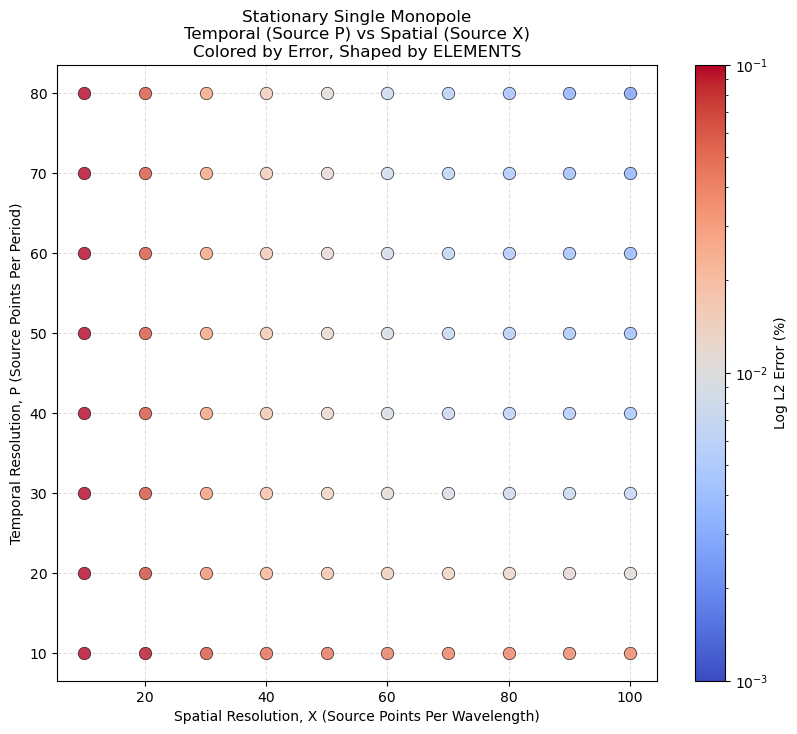

In [14]:
data_single_mono = 'data_260610/single_mono/'
single_mono = FWHDataset.compile_fwh_batch(Path(data_single_mono))
FWHPlotter.plot_px_parameter_space(single_mono, use_doppler=False,
                                   legend=False, add_title="Stationary Single Monopole")

In [ ]:
np.log(2) - np.log(0)

In [ ]:
folders = [
    'data_260610/dual_mono/obs_01',
    'data_260610/dual_mono/obs_02',
    'data_260610/dual_mono/obs_03',
    'data_260610/dual_mono/obs_04',
    'data_260610/dual_mono/obs_05',
]

master = []
for folder in folders:
    master.extend(FWHDataset.compile_fwh_batch(folder, use_doppler=False, error_method='rmse'))

df = pd.DataFrame(master)
obs_01 = df[df['batch_name']=='obs_01']
obs_02 = df[df['batch_name']=='obs_02']
obs_03 = df[df['batch_name']=='obs_03']
obs_04 = df[df['batch_name']=='obs_04']
obs_05 = df[df['batch_name']=='obs_05']
obs_06 = df[df['batch_name']=='obs_06']
obs_07 = df[df['batch_name']=='obs_07']
obs_08 = df[df['batch_name']=='obs_08']

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=df, x='batch_name', y='error', palette='coolwarm', 
            boxprops=dict(edgecolor='black'), medianprops=dict(color='red', linewidth=2),
            showfliers=False, ax=ax)

medians = df.groupby('batch_name')['error'].median()
obs_names = ['obs_01', 'obs_02', 'obs_03', 'obs_04', 'obs_05', 'obs_06', 'obs_07', 'obs_08']

for i, obs in enumerate(obs_names):
    median_val = medians[obs]
    text_label = f"{median_val:.2e}" 
    ax.text(i, median_val * 1.05, text_label, 
            horizontalalignment='center', size='small', color='black', weight='bold')

# ax.set_yscale('log')
ax.set_ylabel('RMSE Error')
ax.set_xlabel('Observer ID (Front to Rear)')
ax.set_title('Error Variance (Interquartile Range & Outliers)')
ax.grid(True, axis='y', linestyle='--', alpha=0.6)

plt.show()

In [ ]:
folders = [
    # 'data_260610/dual_mono/obs_01',
    'data_260610/dual_mono/obs_02',
    'data_260610/dual_mono/obs_03',
    'data_260610/dual_mono/obs_04',
    # 'data_260610/dual_mono/obs_05',
    'data_260610/dual_mono/obs_06',
    'data_260610/dual_mono/obs_07',
    'data_260610/dual_mono/obs_08',
]

master = []
for folder in folders:
    master.extend(FWHDataset.compile_fwh_batch(folder, use_doppler=False, error_method='l2'))

df = pd.DataFrame(master)
# obs_01 = df[df['batch_name']=='obs_01']
obs_02 = df[df['batch_name']=='obs_02']
obs_03 = df[df['batch_name']=='obs_03']
obs_04 = df[df['batch_name']=='obs_04']
# obs_05 = df[df['batch_name']=='obs_05']
obs_06 = df[df['batch_name']=='obs_06']
obs_07 = df[df['batch_name']=='obs_07']
obs_08 = df[df['batch_name']=='obs_08']

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=df, x='batch_name', y='error', palette='coolwarm', 
            boxprops=dict(edgecolor='black'), medianprops=dict(color='red', linewidth=2),
            showfliers=False, ax=ax)

medians = df.groupby('batch_name')['error'].median()
obs_names = ['obs_02', 'obs_03', 'obs_04','obs_06', 'obs_07', 'obs_08']

for i, obs in enumerate(obs_names):
    median_val = medians[obs]
    text_label = f"{median_val:.2e}" 
    ax.text(i, median_val * 1.05, text_label, 
            horizontalalignment='center', size='small', color='black', weight='bold')

ax.set_yscale('log')
ax.set_ylabel('RMSE Error')
ax.set_xlabel('Observer ID (Front to Rear)')
ax.set_title('Error Variance (Interquartile Range & Outliers)')
ax.grid(True, axis='y', linestyle='--', alpha=0.6)

plt.show()

In [ ]:
FWHPlotter.plot_pressure(
    FWHDataset(Path('data_260610/dual_mono/obs_01/ana_M00.dat')),
    FWHDataset(Path('data_260610/dual_mono/obs_01/P80_X100_M00.dat')),
    ref_col='P_obs',
    title="Dual Monopole: Observer 01, P80 X100",
    labels=['Numerical']
)

In [ ]:
FWHPlotter.plot_pressure(
    FWHDataset(Path('data_260610/dual_mono/obs_03/ana_M00.dat')),
    FWHDataset(Path('data_260610/dual_mono/obs_03/P80_X100_M00.dat')),
    ref_col='P_obs',
    title='Dual Monopole: Observer 03, P80 X100',
    labels=['Numerical']
)

In [ ]:
FWHPlotter.plot_pressure(
    FWHDataset(Path('data_260610/dual_mono/obs_02/ana_M00.dat')),
    FWHDataset(Path('data_260610/dual_mono/obs_02/P80_X100_M00.dat')),
    ref_col='P_obs',
    title='Dual Monopole: Observer 02, P80, X100',
    labels=['Numerical']
)